# 5. SPRINT 3 — Evaluación, interpretabilidad y prototipo
## 5.1 HU09 — Validación del modelo · 5.3 HU10 — Interpretación del modelo

**Proyecto:** *Modelo predictivo de horas de indisponibilidad operativa mediante GBM — Terminal Portuario ENGIE-Ilo.*

**Historia de usuario (TB2):** *Como Investigador, quiero evaluar el desempeño del modelo predictivo, para verificar que cumple los objetivos establecidos.*

| Tarea | Qué se hace en este notebook |
|---|---|
| **T15** | Evaluar en la **partición de prueba** (nunca usada en HU05–HU08) con MAE, RMSE y MAPE (regresores, R² solo referencial) y AUC y F1-score (clasificador). |
| **T16** | Confirmar la selección final en prueba: **GBM vs. LightGBM** para la duración, **XGBoost** para la ocurrencia y **validar la limitación de horas hasta el inicio** frente al piso trivial. |

**Datos:** CSV del 01-01-2024 al 12-08-2026 · horizonte de 6 h · origen al cierre de la hora (t + 1 h).
**Insumos:** los archivos que exporta `Script_V10_HU05_HU06_HU07_HU08.ipynb` (EXPORTACIONES_01.rar y EXPORTACIONES_02.rar) más dos CSV crudos de 5 minutos (oleaje y viento), necesarios para recalcular las variables de excedencia del regresor de duración.

### Protocolo de evaluación (definido **antes** de abrir la partición de prueba)

1. **La prueba no se usa para ajustar nada.** Hiperparámetros, configuración de variables, suavizado y umbral del clasificador se toman **congelados** de HU07/HU08 (`hiperparametros_HU07.json`, `hiperparametros_HU08.json`, `comparacion_clasificacion_HU08.csv`).
2. **Reentrenamiento final:** cada modelo se ajusta con **entrenamiento + validación** (todo lo anterior a la prueba, con la purga de 6 h ya aplicada por HU06) y se evalúa **una sola vez** en la prueba (22-03-2026 18:00 → 12-08-2026 23:00). Como control de trazabilidad también se evalúan los modelos **exportados por HU07** (entrenados solo con la partición de entrenamiento).
3. **Mismas filas y mismas métricas** para el GBM y para cada referencia (piso trivial, franja horaria, persistencia, regresión lineal y, en duración, la referencia adaptativa), y para RF, XGBoost y LightGBM como comparación.
4. **Estabilidad:** la prueba se divide en **4 bloques temporales consecutivos** de igual número de horas (B1–B4), análogos a las 4 ventanas walk-forward.
5. **Criterios de aceptación (TB2):**
   - Duración: MAE ≤ 1.0 h · RMSE ≤ 1.25 h · MAPE ≤ 25 % · MAE ≤ 0.90 × piso · desv. del MAE entre bloques ≤ 0.15 h.
   - Horas hasta el inicio: MAE ≤ 1.5 h · RMSE ≤ 1.75 h · MAPE ≤ 50 % · MAE < mejor referencia · desv. del MAE ≤ 0.10 h.
   - Clasificador: AUC ≥ 0.75 (global) y ≥ 0.70 en cada bloque · F1 ≥ 0.24 (complementaria).
6. **Regla de T16** (misma lógica que el ranking de HU08):
   - Una diferencia de MAE entre dos modelos se considera **real** solo si el intervalo de confianza al 95 % (*bootstrap* por evento) excluye el 0 **y** la diferencia es de al menos **2 %** del MAE (regla de empate de HU08). Para el AUC, IC95 % por día.
   - El GBM se **confirma** como modelo principal si ninguna alternativa es realmente mejor. Si alguna lo fuera, se **propone** el cambio mediante **control de cambios**; no se sustituye automáticamente.
   - Una salida aporta sobre el piso trivial solo si su MAE es **≤ 0.90 × piso** (meta de HU08 y del TB2); si no, se comunica como **estimación aproximada**.

In [1]:
# ==== HU09 - Entorno y configuración ====
import json, glob, subprocess, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib, sklearn
try:
    import xgboost, lightgbm
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'xgboost', 'lightgbm'], check=True)
    import xgboost, lightgbm
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, f1_score,
                             precision_score, recall_score, roc_curve)
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier
warnings.filterwarnings('ignore')

COLOR_NAVY, COLOR_TEAL, COLOR_ORANGE, COLOR_GRAY, COLOR_GOLD, COLOR_RED = '#1B3A5C', '#2A9D8F', '#E9762B', '#9AA5B1', '#E3A857', '#C43D3D'
plt.rcParams['font.family'] = 'DejaVu Sans'

SEMILLA, HORIZONTE_H, ORIGEN_H, MAPE_MIN_H = 42, 6, 1, 1.0
N_BLOQUES, N_BOOT = 4, 2000
TARGET_CLF = 'ocurre_evento_6h'
SALIDAS_REG = ['duracion_indisponibilidad_h', 'horas_hasta_inicio_6h']
META = ['particion', 'apto_modelado', 'racha_apto_h', 'entrenable_clasificador', 'entrenable_regresores', 'frac_imputada_6h', 'frac_imputada_24h']
VARS_METEO = ['velocidad_viento_ms', 'dir_viento_sin', 'dir_viento_cos', 'temperatura_c', 'humedad_relative_pct', 'presion_atmosferica_hpa', 'altura_olas_m']

CRITERIOS = {
    'duracion_indisponibilidad_h': {'MAE_h': 1.0, 'RMSE_h': 1.25, 'MAPE_%': 25.0, 'MAE/piso': 0.90, 'sd_MAE_bloques': 0.15},
    'horas_hasta_inicio_6h':       {'MAE_h': 1.5, 'RMSE_h': 1.75, 'MAPE_%': 50.0, 'sd_MAE_bloques': 0.10},
    TARGET_CLF:                    {'AUC': 0.75, 'AUC_min_bloque': 0.70, 'F1': 0.24},
}

# Insumos de HU09 (todos salen de Script_V10_HU05_HU06_HU07_HU08.ipynb, salvo los dos CSV crudos de 5 min)
INSUMOS = {
    'dataset_features_HU06_sin_escalar.csv': 'EXPORTACIONES_01 · predictores HU06 en unidades originales, objetivos y partición',
    'eventos_limpios_HU05.csv':              'EXPORTACIONES_01 · 230 eventos depurados (variables de régimen y estado operativo)',
    'folds_walk_forward_HU06.csv':           'EXPORTACIONES_01 · ventanas walk-forward (control: la prueba no las toca)',
    'hiperparametros_HU07.json':             'EXPORTACIONES_01 · hiperparámetros del clasificador (sección 3.3)',
    'hiperparametros_HU08.json':             'EXPORTACIONES_01 · hiperparámetros de los regresores en configuración final (GBM, LightGBM, RF, XGBoost)',
    'modelos_HU07.joblib':                   'EXPORTACIONES_01 · modelos finales exportados por HU07 (control de reproducibilidad)',
    'modelos_finales_validacion_HU07.csv':   'EXPORTACIONES_01 · métricas de validación de esos modelos (para la ida y vuelta)',
    'comparacion_clasificacion_HU08.csv':    'EXPORTACIONES_02 · umbral de decisión de cada clasificador (fijado en walk-forward)',
    'comparacion_regresion_HU08.csv':        'EXPORTACIONES_02 · resultados walk-forward (para comparar validación vs. prueba)',
    'columnas_modelo_HU07.json':             'EXPORTACIONES_02 · contrato de columnas y umbrales de excedencia de entrenamiento',
    'Altura_de_Olas-data-*.csv':             'CSV crudo de 5 min (data del Sprint 2) · excedencias de oleaje',
    'Velocidad_de_Viento-data-*.csv':        'CSV crudo de 5 min (data del Sprint 2) · excedencias de viento',
}

# Si los .rar están junto al notebook, se descomprimen aquí (Colab trae unrar)
for rar in sorted(glob.glob('EXPORTACIONES_0*.rar')):
    subprocess.run(['unrar', 'e', '-o-', '-inul', rar, '.'], check=False)
faltan = [f for f in INSUMOS if not glob.glob(f)]
if faltan:
    try:
        from google.colab import files
        print('Faltan estos insumos; súbelos (o sube los .rar y vuelve a ejecutar esta celda):', faltan)
        files.upload()
        for rar in sorted(glob.glob('EXPORTACIONES_0*.rar')):
            subprocess.run(['unrar', 'e', '-o-', '-inul', rar, '.'], check=False)
        faltan = [f for f in INSUMOS if not glob.glob(f)]
    except ImportError:
        pass
assert not faltan, f'Faltan insumos de HU09: {faltan}'
display(pd.DataFrame([(f, glob.glob(f)[0], d) for f, d in INSUMOS.items()], columns=['Insumo', 'Archivo encontrado', 'Para qué se usa']).style.hide(axis='index'))
print(f'scikit-learn {sklearn.__version__} · xgboost {xgboost.__version__} · lightgbm {lightgbm.__version__}')

Insumo,Archivo encontrado,Para qué se usa
dataset_features_HU06_sin_escalar.csv,dataset_features_HU06_sin_escalar.csv,"EXPORTACIONES_01 · predictores HU06 en unidades originales, objetivos y partición"
eventos_limpios_HU05.csv,eventos_limpios_HU05.csv,EXPORTACIONES_01 · 230 eventos depurados (variables de régimen y estado operativo)
folds_walk_forward_HU06.csv,folds_walk_forward_HU06.csv,EXPORTACIONES_01 · ventanas walk-forward (control: la prueba no las toca)
hiperparametros_HU07.json,hiperparametros_HU07.json,EXPORTACIONES_01 · hiperparámetros del clasificador (sección 3.3)
hiperparametros_HU08.json,hiperparametros_HU08.json,"EXPORTACIONES_01 · hiperparámetros de los regresores en configuración final (GBM, LightGBM, RF, XGBoost)"
modelos_HU07.joblib,modelos_HU07.joblib,EXPORTACIONES_01 · modelos finales exportados por HU07 (control de reproducibilidad)
modelos_finales_validacion_HU07.csv,modelos_finales_validacion_HU07.csv,EXPORTACIONES_01 · métricas de validación de esos modelos (para la ida y vuelta)
comparacion_clasificacion_HU08.csv,comparacion_clasificacion_HU08.csv,EXPORTACIONES_02 · umbral de decisión de cada clasificador (fijado en walk-forward)
comparacion_regresion_HU08.csv,comparacion_regresion_HU08.csv,EXPORTACIONES_02 · resultados walk-forward (para comparar validación vs. prueba)
columnas_modelo_HU07.json,columnas_modelo_HU07.json,EXPORTACIONES_02 · contrato de columnas y umbrales de excedencia de entrenamiento


scikit-learn 1.6.1 · xgboost 3.4.1 · lightgbm 4.6.0


### Carga, validación de esquema y apertura de la partición de prueba

In [2]:
# ==== Carga y validación ====
FEAT = pd.read_csv('dataset_features_HU06_sin_escalar.csv', index_col='fecha_hora', parse_dates=['fecha_hora']).sort_index()
EV = pd.read_csv('eventos_limpios_HU05.csv', parse_dates=['fecha_inicio', 'fecha_fin']).sort_values('fecha_inicio').reset_index(drop=True)
FOLDS = pd.read_csv('folds_walk_forward_HU06.csv', parse_dates=['train_ini', 'train_fin', 'val_ini', 'val_fin'])
H07 = json.loads(Path('hiperparametros_HU07.json').read_text(encoding='utf-8'))
H08 = json.loads(Path('hiperparametros_HU08.json').read_text(encoding='utf-8'))
CONTRATO = json.loads(Path('columnas_modelo_HU07.json').read_text(encoding='utf-8'))
UMB_CLF = pd.read_csv('comparacion_clasificacion_HU08.csv').set_index('modelo')['umbral'].to_dict()

idx = FEAT.index
assert idx.is_unique and (idx.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), 'La malla horaria no es continua'
X_HU06 = FEAT[[c for c in FEAT.columns if c not in META + [TARGET_CLF] + SALIDAS_REG]]
assert list(X_HU06.columns) == CONTRATO['modelos'][TARGET_CLF]['columnas'], 'Columnas HU06 distintas del contrato de HU07'
assert CONTRATO['horizonte_h'] == HORIZONTE_H and CONTRATO['origen_al_cierre_h'] == ORIGEN_H

PART = FEAT['particion']
PREVIO = PART.isin(['entrenamiento', 'validacion'])          # todo lo anterior a la prueba
PRUEBA = PART.eq('prueba')
EL_CLF, EL_REG = FEAT['entrenable_clasificador'].eq(1), FEAT['entrenable_regresores'].eq(1)
assert FOLDS['val_fin'].max() < idx[PRUEBA].min(), 'Alguna ventana walk-forward toca la prueba'
assert idx[PREVIO].max() < idx[PRUEBA].min() - pd.Timedelta(hours=HORIZONTE_H - 1), 'No hay purga entre validación y prueba'

# Bloques de estabilidad: 4 tramos consecutivos de igual número de horas dentro de la prueba
h_prueba = idx[PRUEBA]
BLOQUE = pd.Series(np.nan, index=idx)
BLOQUE[PRUEBA] = (np.arange(len(h_prueba)) * N_BLOQUES // len(h_prueba)) + 1
resumen = pd.DataFrame({
    'desde': [idx[PART == p].min() for p in ['entrenamiento', 'validacion', 'prueba']],
    'hasta': [idx[PART == p].max() for p in ['entrenamiento', 'validacion', 'prueba']],
    'horas': [int((PART == p).sum()) for p in ['entrenamiento', 'validacion', 'prueba']],
    'filas clasificador': [int(((PART == p) & EL_CLF).sum()) for p in ['entrenamiento', 'validacion', 'prueba']],
    '% con evento': [round(100 * FEAT.loc[(PART == p) & EL_CLF, TARGET_CLF].mean(), 1) for p in ['entrenamiento', 'validacion', 'prueba']],
    'filas regresor': [int(((PART == p) & EL_REG).sum()) for p in ['entrenamiento', 'validacion', 'prueba']],
}, index=['entrenamiento', 'validación', 'prueba'])
display(resumen)
bloques = pd.DataFrame([{'bloque': f'B{int(b)}', 'desde': idx[BLOQUE == b].min(), 'hasta': idx[BLOQUE == b].max(),
                         'filas clasificador': int((EL_CLF & (BLOQUE == b)).sum()), '% con evento': round(100 * FEAT.loc[EL_CLF & (BLOQUE == b), TARGET_CLF].mean(), 1),
                         'filas regresor': int((EL_REG & (BLOQUE == b)).sum())} for b in range(1, N_BLOQUES + 1)])
display(bloques.style.hide(axis='index'))

,desde,hasta,horas,filas clasificador,% con evento,filas regresor
entrenamiento,2024-01-01 00:00:00,2025-10-30 04:00:00,16037,15231,4.9,746
validación,2025-10-30 11:00:00,2026-03-22 11:00:00,3433,3331,8.3,276
prueba,2026-03-22 18:00:00,2026-08-12 23:00:00,3438,3351,9.3,312


bloque,desde,hasta,filas clasificador,% con evento,filas regresor
B1,2026-03-22 18:00:00,2026-04-27 13:00:00,800,9.800000,78
B2,2026-04-27 14:00:00,2026-06-02 08:00:00,859,6.300000,54
B3,2026-06-02 09:00:00,2026-07-08 04:00:00,860,6.300000,54
B4,2026-07-08 05:00:00,2026-08-12 23:00:00,832,15.100000,126


### Variables de la configuración final del regresor de duración (recalculadas con la misma lógica de HU07 §3.4–3.5)

El regresor de duración usa **19 variables**: régimen (duración media de los últimos 3/5/10/20 eventos **ya terminados**, duración del último evento, n.° de eventos en 30 y 90 días), estado operativo (evento en curso, horas desde su inicio, horas desde el fin del último evento, eventos en 24/72/168 h), horas desde la última excedencia de oleaje y viento (umbrales p95/p99 **aprendidos solo con entrenamiento**, leídos del contrato de HU07) y el día del año. Todas usan solo información anterior al origen; la prueba de causalidad lo verifica.

In [3]:
# ==== Variables de régimen y estado operativo ====
o = (idx + pd.Timedelta(hours=ORIGEN_H)).values.astype('datetime64[ns]')
ini = EV['fecha_inicio'].values.astype('datetime64[ns]'); fin = EV['fecha_fin'].values.astype('datetime64[ns]')
dur = (fin - ini) / np.timedelta64(1, 'h')

def construir_regimen(o, ini, fin, dur):
    orden = np.argsort(fin); fin_ord, dur_ord = fin[orden], dur[orden]
    k = np.searchsorted(fin_ord, o, side='right'); acum = np.concatenate([[0.0], np.cumsum(dur_ord)])
    R = pd.DataFrame(index=idx)
    for n in [3, 5, 10, 20]:
        lo = np.maximum(k - n, 0); cnt = k - lo
        R[f'dur_media_ult{n}_eventos'] = np.where(cnt > 0, (acum[k] - acum[lo]) / np.maximum(cnt, 1), np.nan)
    R['dur_ultimo_evento'] = np.where(k > 0, dur_ord[np.maximum(k - 1, 0)], np.nan)
    for h, etq in [(720, '30d'), (2160, '90d')]:
        R[f'eventos_ultimos_{etq}'] = (np.searchsorted(ini, o, side='right') - np.searchsorted(ini, o - np.timedelta64(h, 'h'), side='right')).astype(float)
    return R

def cargar_5min(patron, factor=1.0):
    x = pd.read_csv(sorted(glob.glob(patron))[0]).iloc[:, :2]; x.columns = ['t', 'v']
    x['t'] = pd.to_datetime(x['t'], errors='coerce')
    x['v'] = pd.to_numeric(x['v'].astype(str).str.replace(',', '.').str.extract(r'(-?\d+(?:\.\d+)?)')[0], errors='coerce') * factor
    return x.dropna(subset=['t']).drop_duplicates('t', keep='last').set_index('t')['v'].sort_index()

OLA_5M = cargar_5min('Altura_de_Olas*.csv')
VIENTO_5M = cargar_5min('Velocidad_de_Viento*.csv', 0.44704)          # mph -> m/s (igual que HU07)
UMB_EXC = CONTRATO['umbrales_excedencia_entrenamiento']               # p95/p99 de ENTRENAMIENTO

def construir_operativo(o, ini, fin, ola, viento):
    H = pd.DataFrame(index=idx)
    p = np.searchsorted(ini, o, side='right') - 1; pc = np.clip(p, 0, None)
    fin_cummax = np.maximum.accumulate(fin)
    en_curso = (p >= 0) & (fin_cummax[pc] > o)
    H['evento_en_curso'] = en_curso.astype(float)
    H['h_desde_inicio_evento'] = np.where(en_curso, (o - ini[pc]) / np.timedelta64(1, 'h'), -1.0)
    fin_ord = np.sort(fin); q = np.searchsorted(fin_ord, o, side='right') - 1
    H['h_desde_fin_ultimo_evento'] = np.where(q >= 0, np.minimum((o - fin_ord[np.clip(q, 0, None)]) / np.timedelta64(1, 'h'), 500), 500)
    for h in [24, 72, 168]:
        H[f'eventos_ultimas_{h}h'] = (np.searchsorted(ini, o, side='right') - np.searchsorted(ini, o - np.timedelta64(h, 'h'), side='right')).astype(float)
    for nom, s in [('ola', ola), ('viento', viento)]:
        for qq in [95, 99]:
            c = (s > UMB_EXC[f'{nom}_p{qq}']).resample('h').sum().reindex(idx).fillna(0)
            ult = pd.Series(np.where(c > 0, np.arange(len(idx)), np.nan), index=idx).ffill().fillna(-1e4)
            H[f'h_desde_exc_{nom}_p{qq}'] = np.minimum(np.arange(len(idx)) - ult, 500)
    H['dia_anio_sin'], H['dia_anio_cos'] = np.sin(2 * np.pi * idx.dayofyear / 365.25), np.cos(2 * np.pi * idx.dayofyear / 365.25)
    return H

REGIMEN = construir_regimen(o, ini, fin, dur)
OPER = construir_operativo(o, ini, fin, OLA_5M, VIENTO_5M)
X_TODAS = X_HU06.join(OPER).join(REGIMEN)
COLS_DUR = CONTRATO['modelos']['duracion_indisponibilidad_h']['columnas']
assert all(c in X_TODAS.columns for c in COLS_DUR), 'Falta alguna columna del contrato de duración'
X_DUR = X_TODAS[COLS_DUR]

# Prueba de causalidad: borrar eventos y lecturas desde la mitad de la serie no cambia ninguna fila anterior
p_ = len(idx) // 2; t_p = np.datetime64(idx[p_]); m_ev = ini < t_p
X_pert = construir_operativo(o, ini[m_ev], np.minimum(fin[m_ev], t_p + np.timedelta64(1, 'h')),
                             OLA_5M[OLA_5M.index < idx[p_]], VIENTO_5M[VIENTO_5M.index < idx[p_]]).join(
         construir_regimen(o, ini[m_ev & (fin < t_p)], fin[m_ev & (fin < t_p)], dur[m_ev & (fin < t_p)]))
causal = X_DUR.iloc[:p_ - 1].fillna(-999).equals(X_pert[COLS_DUR].iloc[:p_ - 1].fillna(-999))
print(f'Variables de duración: {X_DUR.shape[1]}  ·  prueba de causalidad: {"OK" if causal else "FALLA"}'); assert causal

Variables de duración: 19  ·  prueba de causalidad: OK


### Control de reproducibilidad: los modelos exportados por HU07 reproducen sus métricas de validación

Antes de abrir la prueba se comprueba que los insumos se cargaron bien: los tres modelos de `modelos_HU07.joblib` deben reproducir, en la partición de **validación**, las métricas que HU07 dejó en `modelos_finales_validacion_HU07.csv`.

In [4]:
# ==== Ida y vuelta de modelos_HU07.joblib en validación ====
def metricas_reg(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); m = y >= MAPE_MIN_H
    return {'MAE_h': mean_absolute_error(y, p), 'RMSE_h': float(np.sqrt(mean_squared_error(y, p))),
            'MAPE_%': 100 * float(np.mean(np.abs((y[m] - p[m]) / y[m]))) if m.any() else np.nan, 'R2': r2_score(y, p)}

EXP = joblib.load('modelos_HU07.joblib')['modelos_finales']

def predecir_exportado(salida, mask):
    r = EXP[salida]; X = X_TODAS.loc[mask, r['columnas']]
    if salida == TARGET_CLF:
        return r['modelo'].predict_proba(X)[:, 1]
    if r.get('columna_referencia'):
        return REGIMEN.loc[mask, r['columna_referencia']].fillna(r['piso_entrenamiento_h']).values + r['suavizado'] * r['modelo'].predict(X)
    return r['modelo'].predict(X)

VAL = PART.eq('validacion')
ref_val = pd.read_csv('modelos_finales_validacion_HU07.csv')
pv = predecir_exportado(TARGET_CLF, VAL & EL_CLF)
filas = [['ocurre_evento_6h', EXP[TARGET_CLF]['algoritmo'], f"AUC {roc_auc_score(FEAT.loc[VAL & EL_CLF, TARGET_CLF], pv):.3f}", ref_val.iloc[0, 4]]]
for i, s in [(1, 'horas_hasta_inicio_6h'), (2, 'duracion_indisponibilidad_h')]:
    m = metricas_reg(FEAT.loc[VAL & EL_REG, s], predecir_exportado(s, VAL & EL_REG))
    filas.append([s, EXP[s]['algoritmo'], f"MAE {m['MAE_h']:.2f} · RMSE {m['RMSE_h']:.2f} · MAPE {m['MAPE_%']:.1f}%", ref_val.iloc[i, 4]])
display(pd.DataFrame(filas, columns=['Salida', 'Modelo exportado (HU07)', 'Recalculado aquí (validación)', 'Registrado por HU07 (validación)']).style.hide(axis='index'))
assert abs(roc_auc_score(FEAT.loc[VAL & EL_CLF, TARGET_CLF], pv) - EXP[TARGET_CLF]['validacion']['AUC']) < 1e-6
for s in ['horas_hasta_inicio_6h', 'duracion_indisponibilidad_h']:
    assert abs(metricas_reg(FEAT.loc[VAL & EL_REG, s], predecir_exportado(s, VAL & EL_REG))['MAE_h'] - EXP[s]['validacion']['MAE_h']) < 1e-6
print('Reproducibilidad: OK (los insumos y las variables recalculadas coinciden con HU07)')

Salida,Modelo exportado (HU07),Recalculado aquí (validación),Registrado por HU07 (validación)
ocurre_evento_6h,XGBoost,AUC 0.884,AUC 0.884 · F1 0.455 (umbral 0.14)
horas_hasta_inicio_6h,LightGBM optimizado · HU06,MAE 1.48 · RMSE 1.73 · MAPE 43.9%,MAE 1.48 · RMSE 1.73 · MAPE 43.9% (0.99 / 1.00 / 0.98 del piso)
duracion_indisponibilidad_h,LightGBM sobre referencia adaptativa · régimen + estado operativo,MAE 0.75 · RMSE 0.96 · MAPE 12.8%,MAE 0.75 · RMSE 0.96 · MAPE 12.8% (0.86 / 0.89 / 0.92 del piso)


Reproducibilidad: OK (los insumos y las variables recalculadas coinciden con HU07)


## 5.1.1 T15 — Evaluación en la partición de prueba

### T15.1 Regresores: GBM frente a cada referencia (mismas filas, mismas métricas)

Para cada salida se reentrena con **entrenamiento + validación** y se predice la prueba. Configuración de cada modelo:

| Salida | Variables | Esquema (de HU07 §3.5 / HU08) |
|---|---|---|
| Duración | 19 variables de régimen y estado operativo | **referencia adaptativa** (media de los últimos 10 eventos terminados) + suavizado × modelo del residuo |
| Horas hasta el inicio | 177 variables de HU06 | modelo directo |

Las referencias son las de HU08: **piso trivial** (media), **franja horaria**, **persistencia** (último valor ya conocido en el origen) y **regresión lineal** (7 variables meteo-oceanográficas); «mejor referencia» y «bloques que gana» se calculan frente a estas tres, igual que en HU08. En duración se agrega además la **referencia adaptativa sola** (grupo aparte), para medir cuánto aporta el modelo sobre ella.

In [5]:
# ==== T15.1 - Regresores en prueba ====
def modelo_reg(nombre, p):
    p = {k: v for k, v in p.items() if k not in ('suavizado', 'pruebas_optuna')}
    if nombre == 'Random Forest': return RandomForestRegressor(n_jobs=-1, random_state=SEMILLA, **p)
    if nombre == 'GBM':           return GradientBoostingRegressor(random_state=SEMILLA, **p)
    if nombre == 'XGBoost':       return XGBRegressor(n_jobs=-1, random_state=SEMILLA, verbosity=0, **p)
    if nombre == 'LightGBM':      return LGBMRegressor(subsample_freq=1, n_jobs=-1, random_state=SEMILLA, verbose=-1, **p)

def config_final(salida):
    return (X_DUR, 'dur_media_ult10_eventos') if salida == 'duracion_indisponibilidad_h' else (X_HU06, None)

def ajustar_y_predecir(nombre, salida, mt, mv):
    p = H08[f'{salida} | {nombre} · final']; s = float(p.get('suavizado', 1.0))
    X, base = config_final(salida); y = FEAT[salida]
    if nombre in ('Random Forest', 'GBM'): X = X.fillna(-999.0)       # igual que HU08 (scikit-learn no acepta NaN)
    if base is None:
        mod = modelo_reg(nombre, p).fit(X[mt], y[mt]); return mod.predict(X[mv]), mod, s
    b_t = REGIMEN.loc[mt, base].fillna(y[mt].mean()); b_v = REGIMEN.loc[mv, base].fillna(y[mt].mean())
    mod = modelo_reg(nombre, p).fit(X[mt], y[mt] - b_t)
    return b_v.values + s * mod.predict(X[mv]), mod, s

# Persistencia (idéntica a HU08): último valor del objetivo ya conocido en el origen
o_ser = pd.Series(idx + pd.Timedelta(hours=ORIGEN_H), index=idx)
def persistencia(salida):
    y = FEAT[salida]; h = FEAT['horas_hasta_inicio_6h']; d = FEAT['duracion_indisponibilidad_h']; lab = y.notna()
    conocido = o_ser[lab] + pd.to_timedelta(h[lab] + (d[lab] if salida == 'duracion_indisponibilidad_h' else 0), unit='h')
    orden = np.argsort(conocido.values)
    k_t = conocido.values.astype('datetime64[ns]')[orden]; k_o = o_ser[lab].values.astype('datetime64[ns]')[orden]; k_y = y[lab].values[orden]
    mejor = np.zeros(len(k_o), dtype=int); m = 0
    for i in range(len(k_o)):
        if k_o[i] >= k_o[m]: m = i
        mejor[i] = m
    pos = np.searchsorted(k_t, o_ser.values.astype('datetime64[ns]'), side='right') - 1
    return pd.Series(np.where(pos >= 0, k_y[mejor[np.clip(pos, 0, None)]], np.nan), index=idx)

MT, MV = PREVIO & EL_REG, PRUEBA & EL_REG
PRED, MODELOS_REG, GRUPO = {}, {}, {}
for salida in SALIDAS_REG:
    y = FEAT[salida]
    def reg(nombre, grupo, pred): PRED[(salida, nombre)] = np.asarray(pred, float); GRUPO[(salida, nombre)] = grupo
    reg('Piso trivial (media)', 'piso', np.full(int(MV.sum()), y[MT].mean()))
    tab = y[MT].groupby(idx[MT].hour).mean()
    reg('Franja horaria', 'referencia', pd.Series(idx[MV].hour).map(tab).fillna(y[MT].mean()).values)
    reg('Persistencia', 'referencia', persistencia(salida)[MV].fillna(y[MT].mean()).values)
    esc = StandardScaler().fit(X_HU06.loc[MT, VARS_METEO])
    reg('Regresión lineal', 'referencia', LinearRegression().fit(esc.transform(X_HU06.loc[MT, VARS_METEO]), y[MT]).predict(esc.transform(X_HU06.loc[MV, VARS_METEO])))
    if salida == 'duracion_indisponibilidad_h':
        reg('Referencia adaptativa (últimos 10 eventos)', 'ref. adaptativa', REGIMEN.loc[MV, 'dur_media_ult10_eventos'].fillna(y[MT].mean()).values)
    for nombre in ['GBM', 'LightGBM', 'Random Forest', 'XGBoost']:
        pr, mod, s = ajustar_y_predecir(nombre, salida, MT, MV)
        MODELOS_REG[(salida, nombre)] = {'modelo': mod, 'suavizado': s}
        reg(nombre + (' (modelo principal)' if nombre == 'GBM' else ''), 'principal' if nombre == 'GBM' else 'comparativo', pr)
    reg(f"LightGBM exportado HU07 (solo entrenamiento)", 'control', predecir_exportado(salida, MV))

def tabla_reg(salida):
    y = FEAT.loc[MV, salida].values; b = BLOQUE[MV].values; filas = []
    for (s, nombre), p in PRED.items():
        if s != salida: continue
        g = metricas_reg(y, p); mb = [mean_absolute_error(y[b == k], p[b == k]) for k in range(1, N_BLOQUES + 1)]
        filas.append({'grupo': GRUPO[(s, nombre)], 'modelo': nombre, **g, **{f'MAE B{k}': v for k, v in enumerate(mb, 1)}, 'sd_MAE_bloques': np.std(mb, ddof=1)})
    t = pd.DataFrame(filas)
    piso = t.loc[t['grupo'] == 'piso'].iloc[0]; mejor_ref = t.loc[t['grupo'] == 'referencia', 'MAE_h'].min()
    t['MAE/piso'], t['RMSE/piso'], t['MAPE/piso'] = t['MAE_h'] / piso['MAE_h'], t['RMSE_h'] / piso['RMSE_h'], t['MAPE_%'] / piso['MAPE_%']
    t['MAE/mejor_ref'] = t['MAE_h'] / mejor_ref
    for k in range(1, N_BLOQUES + 1):
        ref_k = t.loc[t['grupo'] == 'referencia', f'MAE B{k}'].min()
        t[f'gana B{k}'] = t[f'MAE B{k}'] < ref_k
    t['bloques_que_gana'] = t[[f'gana B{k}' for k in range(1, N_BLOQUES + 1)]].sum(axis=1)
    return t.drop(columns=[f'gana B{k}' for k in range(1, N_BLOQUES + 1)])

RES_REG = {s: tabla_reg(s) for s in SALIDAS_REG}
for s in SALIDAS_REG:
    print(f'\n=== {s} · PRUEBA ({int(MV.sum())} filas, {N_BLOQUES} bloques) ===')
    cols = ['grupo', 'modelo', 'MAE_h', 'RMSE_h', 'MAPE_%', 'R2'] + [f'MAE B{k}' for k in range(1, N_BLOQUES + 1)] + ['sd_MAE_bloques', 'MAE/piso', 'MAE/mejor_ref', 'bloques_que_gana']
    display(RES_REG[s].sort_values('MAE_h')[cols].round(3).style.hide(axis='index'))


=== duracion_indisponibilidad_h · PRUEBA (312 filas, 4 bloques) ===


grupo,modelo,MAE_h,RMSE_h,MAPE_%,R2,MAE B1,MAE B2,MAE B3,MAE B4,sd_MAE_bloques,MAE/piso,MAE/mejor_ref,bloques_que_gana
piso,Piso trivial (media),0.662000,0.862000,10.562000,-0.209000,0.748000,0.868000,0.818000,0.455000,0.185000,1.000000,0.966000,2
referencia,Franja horaria,0.685000,0.876000,10.973000,-0.250000,0.768000,0.884000,0.820000,0.492000,0.173000,1.035000,1.000000,0
control,LightGBM exportado HU07 (solo entrenamiento),0.687000,0.820000,11.841000,-0.094000,0.787000,0.925000,0.844000,0.456000,0.206000,1.037000,1.002000,1
comparativo,XGBoost,0.695000,0.827000,12.027000,-0.114000,0.802000,0.922000,0.851000,0.465000,0.203000,1.049000,1.014000,1
comparativo,LightGBM,0.698000,0.834000,12.064000,-0.131000,0.807000,0.932000,0.851000,0.465000,0.206000,1.054000,1.018000,1
comparativo,Random Forest,0.702000,0.834000,12.162000,-0.132000,0.814000,0.926000,0.852000,0.474000,0.201000,1.060000,1.025000,1
principal,GBM (modelo principal),0.705000,0.836000,12.208000,-0.138000,0.817000,0.927000,0.852000,0.477000,0.200000,1.064000,1.028000,1
ref. adaptativa,Referencia adaptativa (últimos 10 eventos),0.705000,0.837000,12.217000,-0.139000,0.818000,0.928000,0.852000,0.478000,0.200000,1.065000,1.029000,1
referencia,Regresión lineal,0.761000,0.951000,12.414000,-0.472000,0.659000,0.932000,0.831000,0.721000,0.121000,1.149000,1.110000,0
referencia,Persistencia,0.983000,1.222000,17.146000,-1.432000,1.209000,1.353000,0.808000,0.760000,0.294000,1.484000,1.434000,0



=== horas_hasta_inicio_6h · PRUEBA (312 filas, 4 bloques) ===


grupo,modelo,MAE_h,RMSE_h,MAPE_%,R2,MAE B1,MAE B2,MAE B3,MAE B4,sd_MAE_bloques,MAE/piso,MAE/mejor_ref,bloques_que_gana
comparativo,Random Forest,1.458000,1.685000,46.300000,0.049000,1.464000,1.468000,1.428000,1.463000,0.019000,0.972000,0.995000,2
comparativo,LightGBM,1.458000,1.695000,46.697000,0.037000,1.432000,1.555000,1.391000,1.462000,0.070000,0.972000,0.995000,3
referencia,Regresión lineal,1.465000,1.701000,46.186000,0.030000,1.469000,1.466000,1.433000,1.476000,0.019000,0.977000,1.000000,0
control,LightGBM exportado HU07 (solo entrenamiento),1.466000,1.696000,46.742000,0.036000,1.456000,1.518000,1.385000,1.484000,0.057000,0.977000,1.001000,1
principal,GBM (modelo principal),1.470000,1.695000,46.864000,0.037000,1.478000,1.475000,1.452000,1.470000,0.012000,0.980000,1.003000,1
comparativo,XGBoost,1.473000,1.699000,46.837000,0.033000,1.473000,1.478000,1.453000,1.479000,0.012000,0.982000,1.005000,0
referencia,Franja horaria,1.499000,1.733000,47.721000,-0.007000,1.452000,1.564000,1.453000,1.520000,0.055000,0.999000,1.023000,0
piso,Piso trivial (media),1.500000,1.729000,47.660000,-0.002000,1.500000,1.500000,1.500000,1.500000,0.000000,1.000000,1.024000,0
referencia,Persistencia,2.555000,3.056000,86.784000,-2.130000,2.527000,2.540000,2.555000,2.578000,0.022000,1.703000,1.744000,0


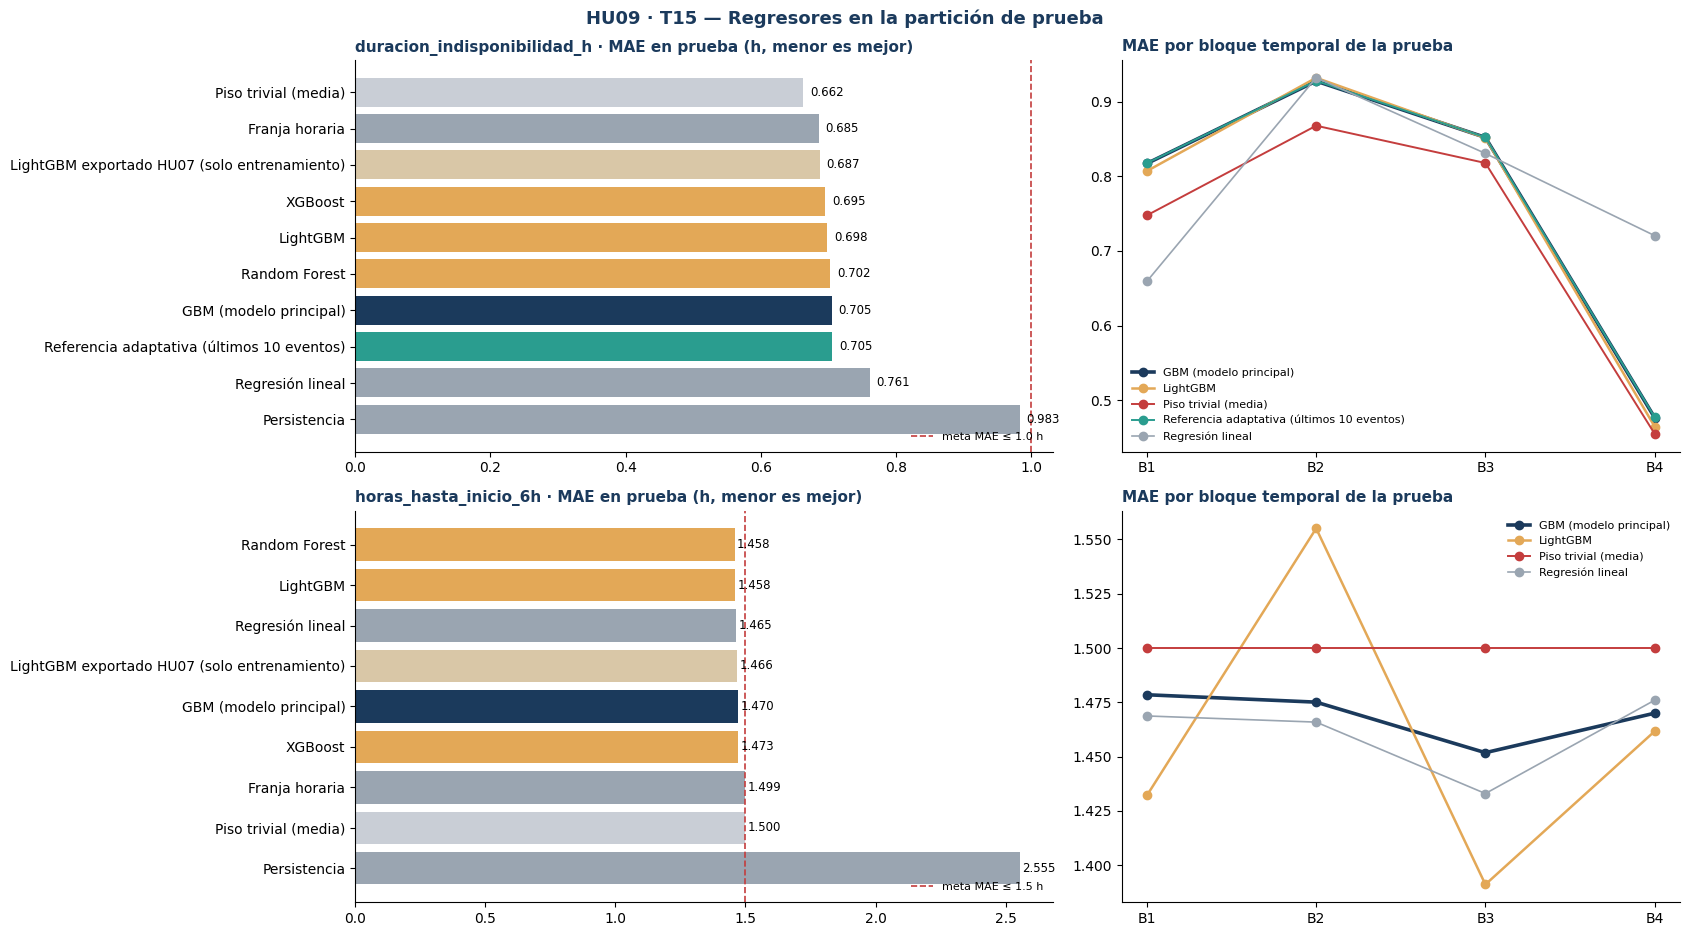

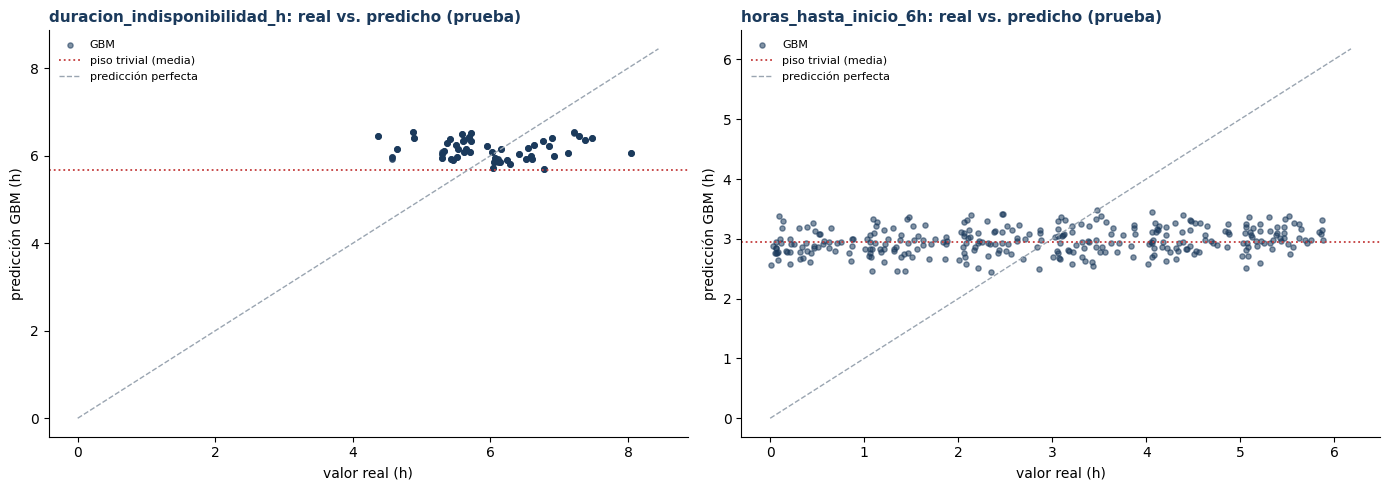

In [6]:
# ==== Vista visual - MAE en prueba por modelo y por bloque ====
COL = {'piso': '#C9CED6', 'referencia': COLOR_GRAY, 'principal': COLOR_NAVY, 'comparativo': COLOR_GOLD, 'control': '#D9C7A7', 'ref. adaptativa': COLOR_TEAL}
fig, axes = plt.subplots(2, 2, figsize=(17, 9.5), gridspec_kw={'width_ratios': [1.25, 1]})
for fila, s in enumerate(SALIDAS_REG):
    t = RES_REG[s].sort_values('MAE_h', ascending=False); ax = axes[fila, 0]
    ax.barh(t['modelo'], t['MAE_h'], color=[COL[g] for g in t['grupo']])
    for yy, v in enumerate(t['MAE_h']): ax.text(v + 0.01, yy, f'{v:.3f}', va='center', fontsize=8.5)
    ax.axvline(CRITERIOS[s]['MAE_h'], color=COLOR_RED, ls='--', lw=1.2, label=f"meta MAE ≤ {CRITERIOS[s]['MAE_h']} h")
    ax.set_title(f'{s} · MAE en prueba (h, menor es mejor)', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold')
    ax.legend(frameon=False, fontsize=8, loc='lower right'); ax.spines[['top', 'right']].set_visible(False)
    ax = axes[fila, 1]
    for nombre, c, lw in [('GBM (modelo principal)', COLOR_NAVY, 2.6), ('LightGBM', COLOR_GOLD, 1.8), ('Piso trivial (media)', COLOR_RED, 1.4),
                          ('Referencia adaptativa (últimos 10 eventos)', COLOR_TEAL, 1.4), ('Regresión lineal', COLOR_GRAY, 1.2)]:
        r = RES_REG[s][RES_REG[s]['modelo'] == nombre]
        if len(r): ax.plot(range(1, N_BLOQUES + 1), r[[f'MAE B{k}' for k in range(1, N_BLOQUES + 1)]].values[0], marker='o', color=c, lw=lw, label=nombre)
    ax.set_xticks(range(1, N_BLOQUES + 1)); ax.set_xticklabels([f'B{k}' for k in range(1, N_BLOQUES + 1)])
    ax.set_title('MAE por bloque temporal de la prueba', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold')
    ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('HU09 · T15 — Regresores en la partición de prueba', fontsize=13, color=COLOR_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, s in zip(axes, SALIDAS_REG):
    y = FEAT.loc[MV, s].values; p = PRED[(s, 'GBM (modelo principal)')]
    ax.scatter(y, p, s=14, alpha=0.55, color=COLOR_NAVY, label='GBM')
    ax.axhline(PRED[(s, 'Piso trivial (media)')][0], color=COLOR_RED, ls=':', lw=1.3, label='piso trivial (media)')
    lim = [0, max(y.max(), p.max()) * 1.05]; ax.plot(lim, lim, color=COLOR_GRAY, ls='--', lw=1, label='predicción perfecta')
    ax.set_xlabel('valor real (h)'); ax.set_ylabel('predicción GBM (h)'); ax.legend(frameon=False, fontsize=8)
    ax.set_title(f'{s}: real vs. predicho (prueba)', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

### T15.2 Clasificador de ocurrencia: XGBoost frente a Random Forest, LightGBM y referencias

Hiperparámetros de HU07 §3.3 y **umbral fijado en walk-forward por HU08** (no se reoptimiza en la prueba). AUC es el criterio principal; F1, precisión y recall son complementarios.

=== ocurre_evento_6h · PRUEBA (3351 filas, 9.3 % con evento) ===


grupo,modelo,umbral,AUC,F1,precision,recall,AUC B1,AUC B2,AUC B3,AUC B4,AUC_min_bloque,AUC_sd_bloques,F1 B1,F1 B2,F1 B3,F1 B4
principal,XGBoost (modelo principal),0.140000,0.875000,0.442000,0.311000,0.763000,0.867000,0.914000,0.888000,0.817000,0.817000,0.041000,0.438000,0.429000,0.438000,0.452000
comparativo,LightGBM,0.110000,0.872000,0.422000,0.288000,0.788000,0.864000,0.910000,0.879000,0.812000,0.812000,0.041000,0.441000,0.407000,0.392000,0.429000
control,XGBoost exportado HU07 (solo entrenamiento),0.140000,0.869000,0.446000,0.321000,0.731000,0.857000,0.914000,0.880000,0.811000,0.811000,0.043000,0.419000,0.436000,0.424000,0.480000
comparativo,Random Forest,0.520000,0.865000,0.444000,0.315000,0.750000,0.852000,0.902000,0.883000,0.809000,0.809000,0.041000,0.457000,0.460000,0.391000,0.450000
referencia,"Trivial (siempre ""habrá evento"")",0.500000,0.500000,0.170000,0.093000,1.000000,0.500000,0.500000,0.500000,0.500000,0.500000,0.000000,0.178000,0.118000,0.118000,0.263000
referencia,Tasa histórica por franja horaria,0.030000,0.479000,0.170000,0.093000,1.000000,0.482000,0.434000,0.520000,0.478000,0.434000,0.035000,0.178000,0.118000,0.118000,0.263000


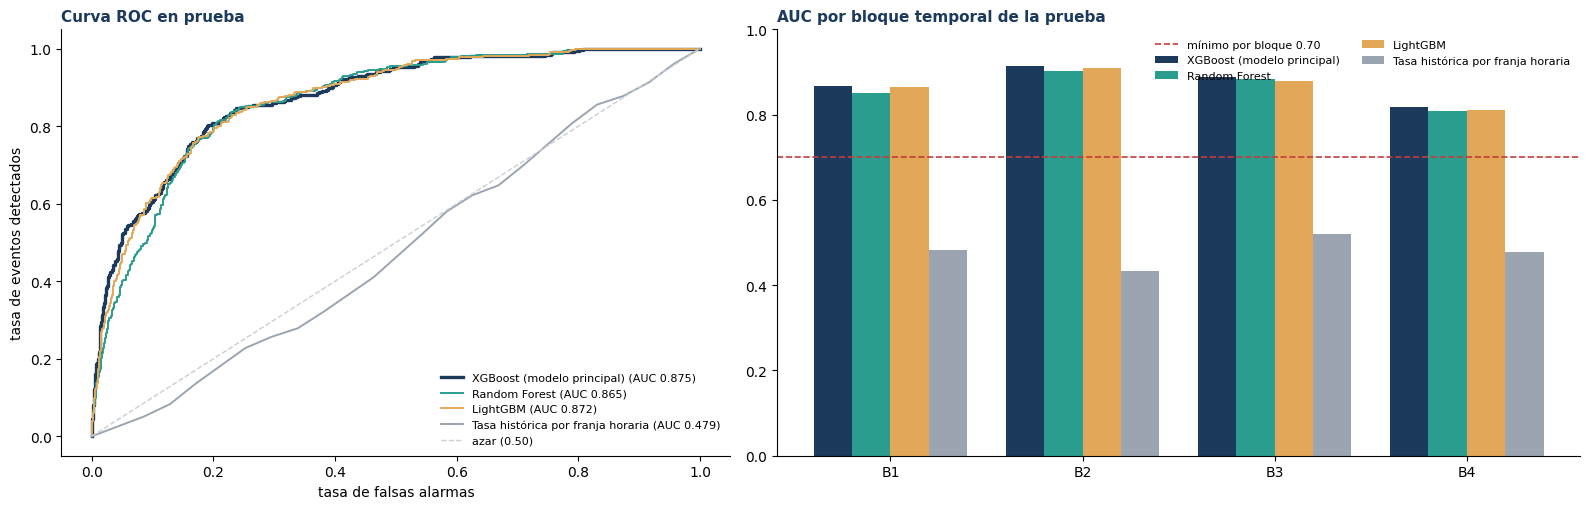

In [7]:
# ==== T15.2 - Clasificador en prueba ====
def modelo_clf(nombre, p):
    p = dict(p)
    if nombre == 'XGBoost':  return XGBClassifier(n_jobs=-1, random_state=SEMILLA, verbosity=0, eval_metric='logloss', **p)
    if nombre == 'LightGBM': return LGBMClassifier(subsample_freq=1, n_jobs=-1, random_state=SEMILLA, verbose=-1, **p)
    if nombre == 'Random Forest':
        p['class_weight'] = None if p.get('class_weight') == 'none' else p.get('class_weight')
        return RandomForestClassifier(bootstrap=True, n_jobs=-1, random_state=SEMILLA, **p)

MTc, MVc = PREVIO & EL_CLF, PRUEBA & EL_CLF
yc_t, yc_v = FEAT.loc[MTc, TARGET_CLF].astype(int), FEAT.loc[MVc, TARGET_CLF].astype(int).values
PROB, UMBRAL, GRUPO_C, MODELOS_CLF = {}, {}, {}, {}
PROB['Trivial (siempre "habrá evento")'], UMBRAL['Trivial (siempre "habrá evento")'], GRUPO_C['Trivial (siempre "habrá evento")'] = np.ones(int(MVc.sum())), 0.5, 'referencia'
tasa = yc_t.groupby(idx[MTc].hour).mean()
PROB['Tasa histórica por franja horaria'] = pd.Series(idx[MVc].hour).map(tasa).fillna(yc_t.mean()).values
UMBRAL['Tasa histórica por franja horaria'], GRUPO_C['Tasa histórica por franja horaria'] = UMB_CLF['Tasa histórica por franja horaria'], 'referencia'
for nombre in ['XGBoost', 'Random Forest', 'LightGBM']:
    mod = modelo_clf(nombre, H07['seccion_3_3'][f'{nombre} | {TARGET_CLF}']['parametros']).fit(X_HU06[MTc], yc_t)
    etq = nombre + (' (modelo principal)' if nombre == 'XGBoost' else '')
    PROB[etq], UMBRAL[etq], GRUPO_C[etq] = mod.predict_proba(X_HU06[MVc])[:, 1], UMB_CLF[nombre], ('principal' if nombre == 'XGBoost' else 'comparativo')
    MODELOS_CLF[nombre] = mod
PROB['XGBoost exportado HU07 (solo entrenamiento)'] = predecir_exportado(TARGET_CLF, MVc)
UMBRAL['XGBoost exportado HU07 (solo entrenamiento)'], GRUPO_C['XGBoost exportado HU07 (solo entrenamiento)'] = EXP[TARGET_CLF]['umbral'], 'control'

bc = BLOQUE[MVc].values
def auc(y, p): return roc_auc_score(y, p) if np.ptp(p) > 0 and 0 < y.mean() < 1 else 0.5
filas = []
for nombre, p in PROB.items():
    u = UMBRAL[nombre]; d = p >= u
    fila = {'grupo': GRUPO_C[nombre], 'modelo': nombre, 'umbral': u, 'AUC': auc(yc_v, p), 'F1': f1_score(yc_v, d),
            'precision': precision_score(yc_v, d, zero_division=0), 'recall': recall_score(yc_v, d)}
    ab = [auc(yc_v[bc == k], p[bc == k]) for k in range(1, N_BLOQUES + 1)]
    fb = [f1_score(yc_v[bc == k], d[bc == k]) for k in range(1, N_BLOQUES + 1)]
    fila.update({f'AUC B{k}': v for k, v in enumerate(ab, 1)}); fila.update({'AUC_min_bloque': min(ab), 'AUC_sd_bloques': np.std(ab, ddof=1)})
    fila.update({f'F1 B{k}': v for k, v in enumerate(fb, 1)})
    filas.append(fila)
RES_CLF = pd.DataFrame(filas)
print(f'=== {TARGET_CLF} · PRUEBA ({int(MVc.sum())} filas, {100 * yc_v.mean():.1f} % con evento) ===')
display(RES_CLF.sort_values('AUC', ascending=False).round(3).style.hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={'width_ratios': [1, 1.2]})
COLC = {'XGBoost (modelo principal)': COLOR_NAVY, 'Random Forest': COLOR_TEAL, 'LightGBM': COLOR_GOLD, 'Tasa histórica por franja horaria': COLOR_GRAY}
for m, c in COLC.items():
    fpr, tpr, _ = roc_curve(yc_v, PROB[m]); axes[0].plot(fpr, tpr, color=c, lw=2.4 if 'principal' in m else 1.4, label=f'{m} (AUC {auc(yc_v, PROB[m]):.3f})')
axes[0].plot([0, 1], [0, 1], color='#C9CED6', ls='--', lw=1, label='azar (0.50)')
axes[0].set_xlabel('tasa de falsas alarmas'); axes[0].set_ylabel('tasa de eventos detectados'); axes[0].legend(frameon=False, fontsize=8, loc='lower right')
axes[0].set_title('Curva ROC en prueba', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold')
w = 0.8 / len(COLC)
for j, (m, c) in enumerate(COLC.items()):
    r = RES_CLF[RES_CLF['modelo'] == m].iloc[0]
    axes[1].bar(np.arange(1, N_BLOQUES + 1) + (j - 1.5) * w, [r[f'AUC B{k}'] for k in range(1, N_BLOQUES + 1)], width=w, color=c, label=m)
axes[1].axhline(CRITERIOS[TARGET_CLF]['AUC_min_bloque'], color=COLOR_RED, ls='--', lw=1.2, label='mínimo por bloque 0.70')
axes[1].set_xticks(range(1, N_BLOQUES + 1)); axes[1].set_xticklabels([f'B{k}' for k in range(1, N_BLOQUES + 1)]); axes[1].set_ylim(0, 1)
axes[1].set_title('AUC por bloque temporal de la prueba', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold'); axes[1].legend(frameon=False, fontsize=8, ncol=2)
for a in axes: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

### T15.3 Contraste con los criterios: aceptación (Sprint 3) vs. indicadores complementarios (TB2)

El TB2 contiene **dos niveles** de criterios, y aquí se reportan por separado:

| Nivel | Qué incluye | Dónde está en el TB2 | Cómo se reporta |
|---|---|---|---|
| **A. Criterios de aceptación (Sprint 3)** | Duración: MAE ≤ 1.0 h · RMSE ≤ 1.25 h · MAPE ≤ 25 % — Horas hasta el inicio: MAE ≤ 1.5 h · RMSE ≤ 1.75 h · MAPE ≤ 50 % — Clasificador: AUC ≥ 0.75 (R² solo referencial; F1 complementaria) | Párrafo de evaluación del Sprint 3 | **CUMPLE / NO CUMPLE** (decide la aceptación de HU09) |
| **B. Indicadores complementarios de valor agregado** | MAE frente al piso trivial (≤ 0.90 ×), MAE frente a la mejor referencia (< 1), estabilidad entre bloques (desv. del MAE ≤ 0.15 / 0.10 h), AUC ≥ 0.70 por bloque, F1 ≥ 0.24 | Tabla de objetivos e indicadores | **CUMPLE / OBSERVACIÓN** (no es fallo de aceptación: indica si la salida es una predicción individualizada o una **estimación aproximada**) |


=== A. Aceptación (Sprint 3) ===


Salida,Modelo,Métrica,Criterio,Prueba,Estado,Lectura
Duración,GBM,MAE (h),≤ 1,0.705000,CUMPLE,
Duración,GBM,RMSE (h),≤ 1.25,0.836000,CUMPLE,
Duración,GBM,MAPE (%),≤ 25,12.200000,CUMPLE,
Horas hasta el inicio,GBM,MAE (h),≤ 1.5,1.470000,CUMPLE,
Horas hasta el inicio,GBM,RMSE (h),≤ 1.75,1.695000,CUMPLE,
Horas hasta el inicio,GBM,MAPE (%),≤ 50,46.900000,CUMPLE,
Ocurrencia en 6 h,XGBoost,AUC,≥ 0.75,0.875000,CUMPLE,
Duración,GBM,R² (solo referencial),—,-0.138000,REFERENCIAL,no decide la aceptación
Horas hasta el inicio,GBM,R² (solo referencial),—,0.037000,REFERENCIAL,no decide la aceptación



=== B. Indicador complementario (TB2) ===


Salida,Modelo,Métrica,Criterio,Prueba,Estado,Lectura
Duración,GBM,MAE / piso trivial,≤ 0.9,1.064000,OBSERVACIÓN,en prueba la media histórica acierta igual o mejor → estimación aproximada
Duración,GBM,Desv. del MAE entre bloques (h),≤ 0.15,0.200000,OBSERVACIÓN,el error varía entre periodos (el piso también: 0.185 h)
Horas hasta el inicio,GBM,MAE / mejor referencia,< 1,1.003000,OBSERVACIÓN,empata con la regresión lineal (diferencia no significativa)
Horas hasta el inicio,GBM,MAE / piso trivial,≤ 0.9,0.980000,OBSERVACIÓN,mejora al piso < 10 % → estimación aproximada
Horas hasta el inicio,GBM,Desv. del MAE entre bloques (h),≤ 0.1,0.012000,CUMPLE,
Ocurrencia en 6 h,XGBoost,AUC mínimo por bloque,≥ 0.7,0.817000,CUMPLE,
Ocurrencia en 6 h,XGBoost,F1-score,≥ 0.24,0.442000,CUMPLE,


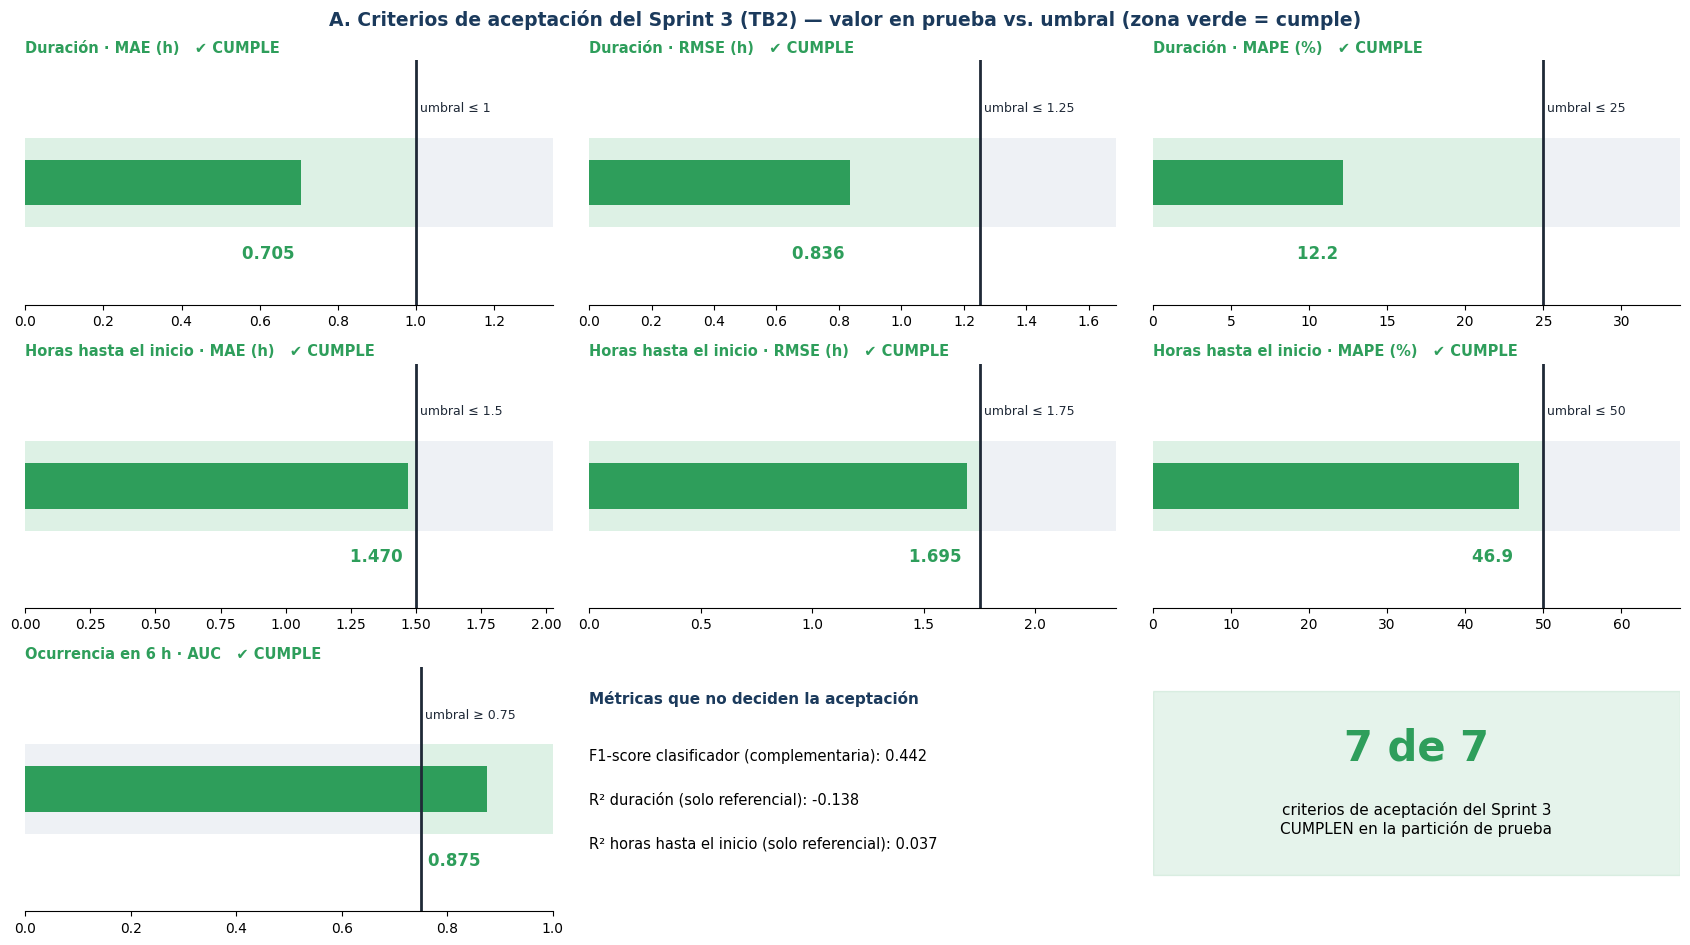

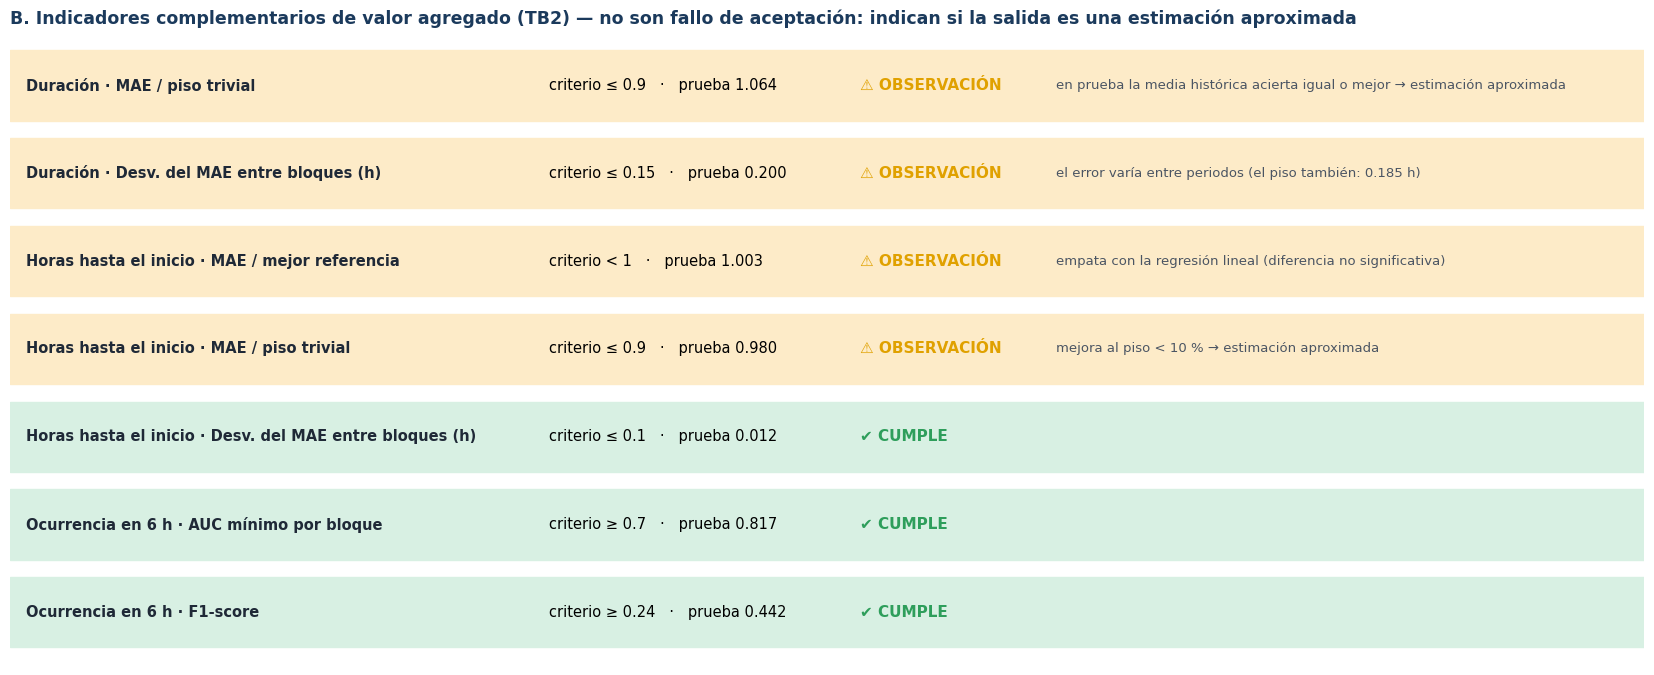


=== Respuesta directa ===


Nivel,Resultado,Estado,Conclusión
"Criterios de aceptación del Sprint 3 (MAE, RMSE, MAPE y AUC)",7 de 7 cumplen,CUMPLE,HU09 se acepta con los criterios del párrafo del Sprint 3.
"Indicadores complementarios (piso, mejor referencia, estabilidad)",3 de 7 cumplen,OBSERVACIÓN,Observaciones: Duración – MAE / piso trivial; Duración – Desv. del MAE entre bloques (h); Horas hasta el inicio – MAE / mejor referencia; Horas hasta el inicio – MAE / piso trivial. Duración y horas hasta el inicio se comunican como estimaciones aproximadas.



=== Validación walk-forward (HU08) vs. prueba (HU09) ===


Salida,Modelo,Walk-forward HU08 (MAE / AUC),Prueba HU09 (MAE / AUC),Walk-forward HU08 (RMSE / F1),Prueba HU09 (RMSE / F1)
duracion_indisponibilidad_h,GBM (modelo principal),0.844,0.705,1.091,0.836
duracion_indisponibilidad_h,LightGBM,0.835,0.698,1.087,0.834
duracion_indisponibilidad_h,Piso trivial (media),1.034,0.662,1.278,0.862
horas_hasta_inicio_6h,GBM (modelo principal),1.492,1.470,1.729,1.695
horas_hasta_inicio_6h,LightGBM,1.487,1.458,1.724,1.695
horas_hasta_inicio_6h,Piso trivial (media),1.500,1.500,1.731,1.729
ocurre_evento_6h,XGBoost (modelo principal),AUC 0.853,AUC 0.875,F1 0.349,F1 0.442
ocurre_evento_6h,Random Forest,AUC 0.845,AUC 0.865,F1 0.345,F1 0.444
ocurre_evento_6h,LightGBM,AUC 0.851,AUC 0.872,F1 0.346,F1 0.422


In [8]:
# ==== T15.3 - Criterios de aceptación (Sprint 3) e indicadores complementarios (TB2) ====
A, B = 'A. Aceptación (Sprint 3)', 'B. Indicador complementario (TB2)'
rD = RES_REG['duracion_indisponibilidad_h'].set_index('modelo').loc['GBM (modelo principal)']
rH = RES_REG['horas_hasta_inicio_6h'].set_index('modelo').loc['GBM (modelo principal)']
rC = RES_CLF.set_index('modelo').loc['XGBoost (modelo principal)']
cD, cH, cC = CRITERIOS['duracion_indisponibilidad_h'], CRITERIOS['horas_hasta_inicio_6h'], CRITERIOS[TARGET_CLF]
# (nivel, salida, modelo, métrica, valor, umbral, sentido, decimales, lectura si no se cumple)
ITEMS = [
    (A, 'Duración', 'GBM', 'MAE (h)', rD['MAE_h'], cD['MAE_h'], '<=', 3, ''),
    (A, 'Duración', 'GBM', 'RMSE (h)', rD['RMSE_h'], cD['RMSE_h'], '<=', 3, ''),
    (A, 'Duración', 'GBM', 'MAPE (%)', rD['MAPE_%'], cD['MAPE_%'], '<=', 1, ''),
    (A, 'Horas hasta el inicio', 'GBM', 'MAE (h)', rH['MAE_h'], cH['MAE_h'], '<=', 3, ''),
    (A, 'Horas hasta el inicio', 'GBM', 'RMSE (h)', rH['RMSE_h'], cH['RMSE_h'], '<=', 3, ''),
    (A, 'Horas hasta el inicio', 'GBM', 'MAPE (%)', rH['MAPE_%'], cH['MAPE_%'], '<=', 1, ''),
    (A, 'Ocurrencia en 6 h', 'XGBoost', 'AUC', rC['AUC'], cC['AUC'], '>=', 3, ''),
    (B, 'Duración', 'GBM', 'MAE / piso trivial', rD['MAE/piso'], cD['MAE/piso'], '<=', 3,
     'en prueba la media histórica acierta igual o mejor → estimación aproximada'),
    (B, 'Duración', 'GBM', 'Desv. del MAE entre bloques (h)', rD['sd_MAE_bloques'], cD['sd_MAE_bloques'], '<=', 3,
     f"el error varía entre periodos (el piso también: {RES_REG['duracion_indisponibilidad_h'].set_index('modelo').loc['Piso trivial (media)', 'sd_MAE_bloques']:.3f} h)"),
    (B, 'Horas hasta el inicio', 'GBM', 'MAE / mejor referencia', rH['MAE/mejor_ref'], 1.0, '<', 3,
     'empata con la regresión lineal (diferencia no significativa)'),
    (B, 'Horas hasta el inicio', 'GBM', 'MAE / piso trivial', rH['MAE/piso'], 0.90, '<=', 3,
     'mejora al piso < 10 % → estimación aproximada'),
    (B, 'Horas hasta el inicio', 'GBM', 'Desv. del MAE entre bloques (h)', rH['sd_MAE_bloques'], cH['sd_MAE_bloques'], '<=', 3, ''),
    (B, 'Ocurrencia en 6 h', 'XGBoost', 'AUC mínimo por bloque', rC['AUC_min_bloque'], cC['AUC_min_bloque'], '>=', 3, ''),
    (B, 'Ocurrencia en 6 h', 'XGBoost', 'F1-score', rC['F1'], cC['F1'], '>=', 3, ''),
]
def _ok(v, u, s): return v <= u if s == '<=' else (v < u if s == '<' else v >= u)
filas = []
for nivel, sal, mod, met, v, u, s, dec, lect in ITEMS:
    ok = _ok(v, u, s)
    est = ('CUMPLE' if ok else 'NO CUMPLE') if nivel == A else ('CUMPLE' if ok else 'OBSERVACIÓN')
    filas.append([nivel, sal, mod, met, f'{s.replace("<=", "≤").replace(">=", "≥")} {u:g}', round(float(v), dec), est, '' if ok else lect])
for sal, r in [('Duración', rD), ('Horas hasta el inicio', rH)]:
    filas.append([A, sal, 'GBM', 'R² (solo referencial)', '—', round(float(r['R2']), 3), 'REFERENCIAL', 'no decide la aceptación'])
CRITERIOS_PRUEBA = pd.DataFrame(filas, columns=['Nivel', 'Salida', 'Modelo', 'Métrica', 'Criterio', 'Prueba', 'Estado', 'Lectura'])

def _color(v):
    return {'CUMPLE': 'background-color:#D8F0E3;color:#14532D;font-weight:bold', 'NO CUMPLE': 'background-color:#F8D7D7;color:#7F1D1D;font-weight:bold',
            'OBSERVACIÓN': 'background-color:#FDEBC8;color:#7A4B00;font-weight:bold', 'REFERENCIAL': 'color:#6B7280'}.get(v, '')
for nivel in [A, B]:
    print(f'\n=== {nivel} ===')
    display(CRITERIOS_PRUEBA[CRITERIOS_PRUEBA['Nivel'] == nivel].drop(columns='Nivel').style.map(_color, subset=['Estado']).hide(axis='index'))

# ---------------- Gráfico 1: criterios de aceptación del Sprint 3 (valor vs. umbral)
acc = [it for it in ITEMS if it[0] == A]
n_ok_A = sum(_ok(it[4], it[5], it[6]) for it in acc)
fig, axes = plt.subplots(3, 3, figsize=(17, 9.6))
layout = {('Duración', 'MAE (h)'): (0, 0), ('Duración', 'RMSE (h)'): (0, 1), ('Duración', 'MAPE (%)'): (0, 2),
          ('Horas hasta el inicio', 'MAE (h)'): (1, 0), ('Horas hasta el inicio', 'RMSE (h)'): (1, 1), ('Horas hasta el inicio', 'MAPE (%)'): (1, 2),
          ('Ocurrencia en 6 h', 'AUC'): (2, 0)}
for nivel, sal, mod, met, v, u, s, dec, _ in acc:
    ax = axes[layout[(sal, met)]]; ok = _ok(v, u, s); col = '#2E9E5B' if ok else COLOR_RED
    tope = 1.0 if met == 'AUC' else max(v, u) * 1.35
    ax.barh([0], [tope], color='#EEF1F5', height=0.55)
    if s == '<=': ax.barh([0], [u], color='#DDF1E5', height=0.55)                 # zona que cumple
    else:         ax.barh([0], [tope - u], left=u, color='#DDF1E5', height=0.55)
    ax.barh([0], [v], color=col, height=0.28)
    ax.axvline(u, color='#1F2937', lw=2); ax.text(u, 0.42, f' umbral {s.replace("<=", "≤").replace(">=", "≥")} {u:g}', fontsize=9, color='#1F2937', va='bottom')
    ax.text(v, -0.38, f'{v:.{dec}f} ', ha='right', va='top', fontsize=12, fontweight='bold', color=col)
    ax.set_xlim(0, tope); ax.set_ylim(-0.75, 0.75); ax.set_yticks([])
    ax.set_title(f"{sal} · {met}   {'✔ CUMPLE' if ok else '✘ NO CUMPLE'}", loc='left', fontsize=10.5, fontweight='bold', color=col)
    ax.spines[['top', 'right', 'left']].set_visible(False)
ax = axes[2, 1]   # F1 (complementaria) y R² (referencial) como contexto
ax.axis('off')
ax.text(0, 0.85, 'Métricas que no deciden la aceptación', fontsize=11, fontweight='bold', color=COLOR_NAVY, transform=ax.transAxes)
ax.text(0, 0.62, f"F1-score clasificador (complementaria): {rC['F1']:.3f}", fontsize=10.5, transform=ax.transAxes)
ax.text(0, 0.44, f"R² duración (solo referencial): {rD['R2']:.3f}", fontsize=10.5, transform=ax.transAxes)
ax.text(0, 0.26, f"R² horas hasta el inicio (solo referencial): {rH['R2']:.3f}", fontsize=10.5, transform=ax.transAxes)
ax = axes[2, 2]; ax.axis('off')
ax.add_patch(plt.Rectangle((0, 0.15), 1, 0.75, transform=ax.transAxes, color='#2E9E5B' if n_ok_A == len(acc) else COLOR_RED, alpha=0.12))
ax.text(0.5, 0.62, f'{n_ok_A} de {len(acc)}', ha='center', fontsize=30, fontweight='bold', color='#2E9E5B' if n_ok_A == len(acc) else COLOR_RED, transform=ax.transAxes)
ax.text(0.5, 0.32, 'criterios de aceptación del Sprint 3\nCUMPLEN en la partición de prueba', ha='center', fontsize=11, transform=ax.transAxes)
fig.suptitle('A. Criterios de aceptación del Sprint 3 (TB2) — valor en prueba vs. umbral (zona verde = cumple)', fontsize=13.5, color=COLOR_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

# ---------------- Gráfico 2: indicadores complementarios (valor agregado) como semáforo
comp = [it for it in ITEMS if it[0] == B]
fig, ax = plt.subplots(figsize=(17, 0.75 * len(comp) + 1.6))
for i, (nivel, sal, mod, met, v, u, s, dec, lect) in enumerate(comp[::-1]):
    ok = _ok(v, u, s); col = '#2E9E5B' if ok else '#E0A100'
    ax.add_patch(plt.Rectangle((0, i - 0.4), 1, 0.8, color='#D8F0E3' if ok else '#FDEBC8'))
    ax.text(0.01, i, f'{sal} · {met}', va='center', fontsize=10.5, fontweight='bold', color='#1F2937')
    ax.text(0.33, i, f"criterio {s.replace('<=', '≤').replace('>=', '≥')} {u:g}   ·   prueba {v:.{dec}f}", va='center', fontsize=10.5)
    ax.text(0.52, i, '✔ CUMPLE' if ok else '⚠ OBSERVACIÓN', va='center', fontsize=11, fontweight='bold', color=col)
    ax.text(0.64, i, lect, va='center', fontsize=9.5, color='#4B5563', wrap=True)
ax.set_xlim(0, 1); ax.set_ylim(-0.6, len(comp) - 0.4); ax.axis('off')
ax.set_title('B. Indicadores complementarios de valor agregado (TB2) — no son fallo de aceptación: indican si la salida es una estimación aproximada',
             loc='left', fontsize=12.5, color=COLOR_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

# ---------------- Respuesta directa
obs = CRITERIOS_PRUEBA[CRITERIOS_PRUEBA['Estado'] == 'OBSERVACIÓN']
RESPUESTA = pd.DataFrame([
    ['Criterios de aceptación del Sprint 3 (MAE, RMSE, MAPE y AUC)', f'{n_ok_A} de {len(acc)} cumplen',
     'CUMPLE' if n_ok_A == len(acc) else 'NO CUMPLE', 'HU09 se acepta con los criterios del párrafo del Sprint 3.'],
    ['Indicadores complementarios (piso, mejor referencia, estabilidad)', f"{len(comp) - len(obs)} de {len(comp)} cumplen",
     'OBSERVACIÓN' if len(obs) else 'CUMPLE',
     'Observaciones: ' + '; '.join(f"{r['Salida']} – {r['Métrica']}" for _, r in obs.iterrows()) +
     '. Duración y horas hasta el inicio se comunican como estimaciones aproximadas.' if len(obs) else 'Sin observaciones.'],
], columns=['Nivel', 'Resultado', 'Estado', 'Conclusión'])
print('\n=== Respuesta directa ===')
display(RESPUESTA.style.map(_color, subset=['Estado']).hide(axis='index'))

# Validación (walk-forward, HU08) vs. prueba: ¿se mantiene el desempeño?
wf = pd.read_csv('comparacion_regresion_HU08.csv'); wfc = pd.read_csv('comparacion_clasificacion_HU08.csv')
comp_vp = []
for s in SALIDAS_REG:
    for nombre, n8 in [('GBM (modelo principal)', 'GBM · final'), ('LightGBM', 'LightGBM · final'), ('Piso trivial (media)', 'Media global (piso trivial)')]:
        a = wf[(wf['salida'] == s) & (wf['modelo'] == n8)].iloc[0]; b = RES_REG[s].set_index('modelo').loc[nombre]
        comp_vp.append([s, nombre, f"{a['MAE_h']:.3f}", f"{b['MAE_h']:.3f}", f"{a['RMSE_h']:.3f}", f"{b['RMSE_h']:.3f}"])
for nombre, n8 in [('XGBoost (modelo principal)', 'XGBoost'), ('Random Forest', 'Random Forest'), ('LightGBM', 'LightGBM')]:
    a = wfc[wfc['modelo'] == n8].iloc[0]; b = RES_CLF.set_index('modelo').loc[nombre]
    comp_vp.append([TARGET_CLF, nombre, f"AUC {a['AUC']:.3f}", f"AUC {b['AUC']:.3f}", f"F1 {a['F1']:.3f}", f"F1 {b['F1']:.3f}"])
print('\n=== Validación walk-forward (HU08) vs. prueba (HU09) ===')
display(pd.DataFrame(comp_vp, columns=['Salida', 'Modelo', 'Walk-forward HU08 (MAE / AUC)', 'Prueba HU09 (MAE / AUC)', 'Walk-forward HU08 (RMSE / F1)', 'Prueba HU09 (RMSE / F1)']).style.hide(axis='index'))

## 5.1.2 T16 — Confirmación de la selección final en prueba

Se aplica la regla declarada en el protocolo. Para no confundir una diferencia pequeña con una mejora real, se calcula el **intervalo de confianza al 95 %** de cada diferencia con *bootstrap* por **evento** (las filas que miran al mismo evento se remuestrean juntas, porque no son independientes) y, en el clasificador, por **día**.

| Salida | Comparación | Se confirma si… |
|---|---|---|
| Duración | GBM vs. LightGBM (y vs. RF, XGBoost, referencia adaptativa y piso) | ninguna alternativa es realmente mejor (IC95 % excluye el 0 **y** diferencia ≥ 2 %) |
| Ocurrencia | XGBoost vs. Random Forest y LightGBM | XGBoost cumple AUC/F1 y ninguna alternativa tiene un AUC significativamente mayor |
| Horas hasta el inicio | GBM vs. piso trivial | se **valida la limitación** si el MAE del GBM es > 0.90 × piso (no alcanza la mejora del 10 % exigida), aunque la diferencia sea estadísticamente significativa |

In [9]:
# ==== T16 - Bootstrap por evento / por día y decisión final ====
rng = np.random.default_rng(SEMILLA)
ev_id = (o_ser[MV] + pd.to_timedelta(FEAT.loc[MV, 'horas_hasta_inicio_6h'], unit='h')).dt.round('min').values   # inicio del evento al que mira cada fila
grupos_ev = pd.factorize(ev_id)[0]; n_ev = grupos_ev.max() + 1
filas_por_ev = [np.where(grupos_ev == g)[0] for g in range(n_ev)]

def ic_diferencia_mae(s, a, b):
    y = FEAT.loc[MV, s].values; ea, eb = np.abs(y - PRED[(s, a)]), np.abs(y - PRED[(s, b)])
    dif = []
    for _ in range(N_BOOT):
        sel = np.concatenate([filas_por_ev[g] for g in rng.integers(0, n_ev, n_ev)])
        dif.append(ea[sel].mean() - eb[sel].mean())
    return ea.mean() - eb.mean(), np.percentile(dif, 2.5), np.percentile(dif, 97.5)

dia = pd.factorize(idx[MVc].normalize())[0]; n_dia = dia.max() + 1; filas_por_dia = [np.where(dia == g)[0] for g in range(n_dia)]
def ic_diferencia_auc(a, b):
    pa, pb = PROB[a], PROB[b]; dif = []
    for _ in range(N_BOOT // 2):
        sel = np.concatenate([filas_por_dia[g] for g in rng.integers(0, n_dia, n_dia)])
        if 0 < yc_v[sel].mean() < 1: dif.append(roc_auc_score(yc_v[sel], pa[sel]) - roc_auc_score(yc_v[sel], pb[sel]))
    return auc(yc_v, pa) - auc(yc_v, pb), np.percentile(dif, 2.5), np.percentile(dif, 97.5)

D, H = 'duracion_indisponibilidad_h', 'horas_hasta_inicio_6h'
EMPATE = 0.02                                                     # regla de empate de HU08
def lectura_mae(s, a, b, d, lo, hi):
    if lo <= 0 <= hi: return 'sin diferencia significativa'
    base = RES_REG[s].set_index('modelo').loc[b, 'MAE_h']; ganador = a.split(' (')[0] if hi < 0 else b
    return f'{ganador} mejor' + ('' if abs(d) / base >= EMPATE else f' (significativa pero < {EMPATE:.0%}: empate práctico)')

comparaciones = [
    (D, 'GBM (modelo principal)', 'LightGBM'), (D, 'GBM (modelo principal)', 'Random Forest'), (D, 'GBM (modelo principal)', 'XGBoost'),
    (D, 'GBM (modelo principal)', 'Referencia adaptativa (últimos 10 eventos)'), (D, 'GBM (modelo principal)', 'Piso trivial (media)'),
    (H, 'GBM (modelo principal)', 'LightGBM'), (H, 'GBM (modelo principal)', 'Random Forest'), (H, 'GBM (modelo principal)', 'Regresión lineal'),
    (H, 'GBM (modelo principal)', 'Piso trivial (media)'),
]
filas = []
for s, a, b in comparaciones:
    d, lo, hi = ic_diferencia_mae(s, a, b)
    filas.append([s, f'MAE: {a} − {b}', round(d, 3), f'[{lo:+.3f}; {hi:+.3f}]', lectura_mae(s, a, b, d, lo, hi)])
for b in ['Random Forest', 'LightGBM']:
    d, lo, hi = ic_diferencia_auc('XGBoost (modelo principal)', b)
    filas.append([TARGET_CLF, f'AUC: XGBoost − {b}', round(d, 3), f'[{lo:+.3f}; {hi:+.3f}]', 'sin diferencia significativa' if lo <= 0 <= hi else ('XGBoost mejor' if lo > 0 else f'{b} mejor')])
IC_T16 = pd.DataFrame(filas, columns=['Salida', 'Diferencia (prueba)', 'Valor', 'IC 95 % (bootstrap)', 'Lectura'])
print(f'Bootstrap: {N_BOOT} remuestreos · {n_ev} eventos en la prueba del regresor · {n_dia} días en la prueba del clasificador')
display(IC_T16.style.hide(axis='index'))

# ---- Decisión
def fila_ic(s, txt): return IC_T16[(IC_T16['Salida'] == s) & (IC_T16['Diferencia (prueba)'].str.contains(txt, regex=False))].iloc[0]
def criterios_txt(salida, nivel):
    t = CRITERIOS_PRUEBA[(CRITERIOS_PRUEBA['Salida'] == salida) & (CRITERIOS_PRUEBA['Nivel'] == nivel) & (CRITERIOS_PRUEBA['Estado'] != 'REFERENCIAL')]
    no = t.loc[t['Estado'] != 'CUMPLE', 'Métrica'].tolist()
    if nivel == A: return 'CUMPLE (' + ', '.join(t['Métrica']) + ')' if not no else 'NO CUMPLE: ' + ', '.join(no)
    return 'CUMPLE' if not no else 'OBSERVACIÓN: ' + ', '.join(no)
def realmente_mejor(salida, alternativas):
    return [b for b in alternativas if fila_ic(salida, f'− {b}')['Lectura'] == f'{b} mejor']
rD, rH, rC = RES_REG[D].set_index('modelo'), RES_REG[H].set_index('modelo'), RES_CLF.set_index('modelo')
mej_D = realmente_mejor(D, ['LightGBM', 'Random Forest', 'XGBoost'])
mej_C = [b for b in ['Random Forest', 'LightGBM'] if fila_ic(TARGET_CLF, f'− {b}')['Lectura'] == f'{b} mejor']
mej_H = realmente_mejor(H, ['LightGBM', 'Random Forest'])
ratio_D, ratio_H = rD.loc['GBM (modelo principal)', 'MAE/piso'], rH.loc['GBM (modelo principal)', 'MAE/piso']
DECISION = pd.DataFrame([
    ['Duración del evento', 'GBM vs. LightGBM',
     f"GBM MAE {rD.loc['GBM (modelo principal)', 'MAE_h']:.3f} h · LightGBM {rD.loc['LightGBM', 'MAE_h']:.3f} h · IC95 % de la diferencia {fila_ic(D, '− LightGBM')['IC 95 % (bootstrap)']}",
     'GBM CONFIRMADO (ninguna alternativa es realmente mejor)' if not mej_D else f"PROPONER CAMBIO a {mej_D[0]} vía control de cambios",
     criterios_txt('Duración', A), criterios_txt('Duración', B),
     ('Aporta sobre el piso' if ratio_D <= 0.90 else
      f"En prueba NO mejora al piso trivial (MAE ×{ratio_D:.2f}; IC95 % {fila_ic(D, '− Piso trivial')['IC 95 % (bootstrap)']}) y equivale a la referencia adaptativa (suavizado {MODELOS_REG[(D, 'GBM')]['suavizado']:.3f}): la duración se comunica como estimación aproximada")],
    ['Ocurrencia en 6 h', 'XGBoost vs. RF / LightGBM',
     f"XGBoost AUC {rC.loc['XGBoost (modelo principal)', 'AUC']:.3f} · RF {rC.loc['Random Forest', 'AUC']:.3f} · LightGBM {rC.loc['LightGBM', 'AUC']:.3f} · F1 {rC.loc['XGBoost (modelo principal)', 'F1']:.3f}",
     'XGBoost CONFIRMADO como clasificador' if not mej_C else f'PROPONER CAMBIO a {mej_C[0]} vía control de cambios',
     criterios_txt('Ocurrencia en 6 h', A), criterios_txt('Ocurrencia en 6 h', B), 'Supera ampliamente a las referencias (AUC ≈ 0.50)'],
    ['Horas hasta el inicio', 'GBM vs. piso trivial',
     f"GBM MAE {rH.loc['GBM (modelo principal)', 'MAE_h']:.3f} h · piso {rH.loc['Piso trivial (media)', 'MAE_h']:.3f} h (×{ratio_H:.3f}) · IC95 % {fila_ic(H, '− Piso trivial')['IC 95 % (bootstrap)']}",
     'GBM se mantiene' + ('' if not mej_H else f' (aunque {mej_H[0]} es mejor: proponer cambio)'),
     criterios_txt('Horas hasta el inicio', A), criterios_txt('Horas hasta el inicio', B),
     ('LIMITACIÓN VALIDADA: ' if ratio_H > 0.90 else 'Sin limitación: ') +
     f"mejora frente al piso de {rH.loc['Piso trivial (media)', 'MAE_h'] - rH.loc['GBM (modelo principal)', 'MAE_h']:.3f} h ({100 * (1 - ratio_H):.1f} %), "
     + ('muy por debajo del 10 % exigido: la salida se comunica como estimación aproximada' if ratio_H > 0.90 else 'alcanza la mejora exigida')],
], columns=['Salida', 'Comparación T16', 'Evidencia en prueba', 'Selección', 'Aceptación (Sprint 3)', 'Indicadores complementarios (TB2)', 'Observación'])
print('\n=== Decisión T16 ===')
display(DECISION.style.hide(axis='index'))

Bootstrap: 2000 remuestreos · 52 eventos en la prueba del regresor · 143 días en la prueba del clasificador


Salida,Diferencia (prueba),Valor,IC 95 % (bootstrap),Lectura
duracion_indisponibilidad_h,MAE: GBM (modelo principal) − LightGBM,0.007000,[-0.008; +0.022],sin diferencia significativa
duracion_indisponibilidad_h,MAE: GBM (modelo principal) − Random Forest,0.002000,[+0.001; +0.004],Random Forest mejor (significativa pero < 2%: empate práctico)
duracion_indisponibilidad_h,MAE: GBM (modelo principal) − XGBoost,0.010000,[-0.001; +0.020],sin diferencia significativa
duracion_indisponibilidad_h,MAE: GBM (modelo principal) − Referencia adaptativa (últimos 10 eventos),-0.000000,[-0.001; -0.000],GBM mejor (significativa pero < 2%: empate práctico)
duracion_indisponibilidad_h,MAE: GBM (modelo principal) − Piso trivial (media),0.042000,[-0.099; +0.179],sin diferencia significativa
horas_hasta_inicio_6h,MAE: GBM (modelo principal) − LightGBM,0.012000,[-0.014; +0.036],sin diferencia significativa
horas_hasta_inicio_6h,MAE: GBM (modelo principal) − Random Forest,0.012000,[+0.002; +0.022],Random Forest mejor (significativa pero < 2%: empate práctico)
horas_hasta_inicio_6h,MAE: GBM (modelo principal) − Regresión lineal,0.005000,[-0.015; +0.024],sin diferencia significativa
horas_hasta_inicio_6h,MAE: GBM (modelo principal) − Piso trivial (media),-0.030000,[-0.045; -0.015],GBM mejor
ocurre_evento_6h,AUC: XGBoost − Random Forest,0.010000,[+0.002; +0.019],XGBoost mejor



=== Decisión T16 ===


Salida,Comparación T16,Evidencia en prueba,Selección,Aceptación (Sprint 3),Indicadores complementarios (TB2),Observación
Duración del evento,GBM vs. LightGBM,GBM MAE 0.705 h · LightGBM 0.698 h · IC95 % de la diferencia [-0.008; +0.022],GBM CONFIRMADO (ninguna alternativa es realmente mejor),"CUMPLE (MAE (h), RMSE (h), MAPE (%))","OBSERVACIÓN: MAE / piso trivial, Desv. del MAE entre bloques (h)",En prueba NO mejora al piso trivial (MAE ×1.06; IC95 % [-0.099; +0.179]) y equivale a la referencia adaptativa (suavizado 0.004): la duración se comunica como estimación aproximada
Ocurrencia en 6 h,XGBoost vs. RF / LightGBM,XGBoost AUC 0.875 · RF 0.865 · LightGBM 0.872 · F1 0.442,XGBoost CONFIRMADO como clasificador,CUMPLE (AUC),CUMPLE,Supera ampliamente a las referencias (AUC ≈ 0.50)
Horas hasta el inicio,GBM vs. piso trivial,GBM MAE 1.470 h · piso 1.500 h (×0.980) · IC95 % [-0.045; -0.015],GBM se mantiene,"CUMPLE (MAE (h), RMSE (h), MAPE (%))","OBSERVACIÓN: MAE / mejor referencia, MAE / piso trivial","LIMITACIÓN VALIDADA: mejora frente al piso de 0.030 h (2.0 %), muy por debajo del 10 % exigido: la salida se comunica como estimación aproximada"


### Exportación de entregables de HU09

| Archivo | Contenido |
|---|---|
| `resultados_prueba_regresion_HU09.csv` | métricas en prueba de cada regresor y referencia (global y por bloque) |
| `resultados_prueba_clasificacion_HU09.csv` | AUC, F1, precisión y recall en prueba (global y por bloque) |
| `criterios_aceptacion_prueba_HU09.csv` | criterio, valor en prueba y estado |
| `decision_T16_HU09.csv` · `ic_bootstrap_T16_HU09.csv` | decisión de T16 y sus intervalos de confianza |
| `predicciones_prueba_HU09.csv` | predicciones fila a fila en la prueba (para HU10/HU12) |
| `modelos_finales_HU09.joblib` | los tres modelos confirmados, **reentrenados con entrenamiento + validación**, con su fórmula de predicción y umbral |

In [10]:
# ==== Exportación ====
pd.concat([t.assign(salida=s) for s, t in RES_REG.items()]).to_csv('resultados_prueba_regresion_HU09.csv', index=False)
RES_CLF.to_csv('resultados_prueba_clasificacion_HU09.csv', index=False)
CRITERIOS_PRUEBA.to_csv('criterios_aceptacion_prueba_HU09.csv', index=False)
DECISION.to_csv('decision_T16_HU09.csv', index=False); IC_T16.to_csv('ic_bootstrap_T16_HU09.csv', index=False)
pr_reg = pd.DataFrame({f'{s} | {n}': p for (s, n), p in PRED.items()}, index=idx[MV]).assign(**{f'real | {s}': FEAT.loc[MV, s] for s in SALIDAS_REG}, bloque=BLOQUE[MV])
pr_clf = pd.DataFrame({f'{TARGET_CLF} | {n}': p for n, p in PROB.items()}, index=idx[MVc]).assign(**{f'real | {TARGET_CLF}': yc_v, 'bloque': BLOQUE[MVc]})
pr_clf.join(pr_reg.drop(columns='bloque'), how='left').rename_axis('fecha_hora').to_csv('predicciones_prueba_HU09.csv')

alg_dur = 'GBM'   # el cambio de algoritmo solo procede vía control de cambios
FINALES_HU09 = {
    TARGET_CLF: {'algoritmo': 'XGBoost', 'modelo': MODELOS_CLF['XGBoost'], 'umbral': UMBRAL['XGBoost (modelo principal)'], 'columnas': list(X_HU06.columns),
                 'prediccion': 'probabilidad = modelo.predict_proba(X)[:, 1]; evento en 6 h si probabilidad >= umbral',
                 'prueba': RES_CLF.set_index('modelo').loc['XGBoost (modelo principal)'][['AUC', 'F1', 'precision', 'recall', 'AUC_min_bloque']].to_dict()},
    D: {'algoritmo': alg_dur, 'modelo': MODELOS_REG[(D, alg_dur)]['modelo'], 'columnas': COLS_DUR, 'columna_referencia': 'dur_media_ult10_eventos',
        'suavizado': MODELOS_REG[(D, alg_dur)]['suavizado'], 'piso_h': float(FEAT.loc[MT, D].mean()), 'nan_centinela': -999.0 if alg_dur == 'GBM' else None,
        'prediccion': 'prediccion = dur_media_ult10_eventos (o piso_h si no existe) + suavizado · modelo.predict(X.fillna(-999))',
        'prueba': RES_REG[D].set_index('modelo').loc['GBM (modelo principal)' if alg_dur == 'GBM' else alg_dur][['MAE_h', 'RMSE_h', 'MAPE_%', 'R2', 'MAE/piso']].to_dict()},
    H: {'algoritmo': 'GBM', 'modelo': MODELOS_REG[(H, 'GBM')]['modelo'], 'columnas': list(X_HU06.columns), 'piso_h': float(FEAT.loc[MT, H].mean()),
        'uso': 'estimación aproximada del inicio (mejora < 10 % frente al piso trivial en prueba)' if ratio_H > 0.90 else 'estimación del inicio',
        'prediccion': 'prediccion = modelo.predict(X.fillna(-999))',
        'prueba': RES_REG[H].set_index('modelo').loc['GBM (modelo principal)'][['MAE_h', 'RMSE_h', 'MAPE_%', 'R2', 'MAE/piso']].to_dict()},
}
joblib.dump({'modelos_finales': FINALES_HU09, 'horizonte_h': HORIZONTE_H, 'origen_al_cierre_h': ORIGEN_H,
             'entrenado_con': 'particiones entrenamiento + validación (hiperparámetros congelados de HU07/HU08)',
             'umbrales_excedencia_entrenamiento': UMB_EXC,
             'versiones': {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'lightgbm': lightgbm.__version__}}, 'modelos_finales_HU09.joblib')
archivos_hu09 = ['resultados_prueba_regresion_HU09.csv', 'resultados_prueba_clasificacion_HU09.csv', 'criterios_aceptacion_prueba_HU09.csv',
                 'decision_T16_HU09.csv', 'ic_bootstrap_T16_HU09.csv', 'predicciones_prueba_HU09.csv', 'modelos_finales_HU09.joblib']
print('Archivos generados:')
for f in archivos_hu09: print(f'  - {f}  ({Path(f).stat().st_size / 1024:,.0f} KB)')

# Ida y vuelta
g = joblib.load('modelos_finales_HU09.joblib')['modelos_finales']
assert np.allclose(g[TARGET_CLF]['modelo'].predict_proba(X_HU06[MVc])[:, 1], PROB['XGBoost (modelo principal)'])
Xd = X_DUR[MV].fillna(-999.0) if g[D]['nan_centinela'] is not None else X_DUR[MV]
assert np.allclose(REGIMEN.loc[MV, 'dur_media_ult10_eventos'].fillna(g[D]['piso_h']).values + g[D]['suavizado'] * g[D]['modelo'].predict(Xd),
                   PRED[(D, 'GBM (modelo principal)' if alg_dur == 'GBM' else alg_dur)])
print('Ida y vuelta de modelos_finales_HU09.joblib: OK')

Archivos generados:
  - resultados_prueba_regresion_HU09.csv  (6 KB)
  - resultados_prueba_clasificacion_HU09.csv  (2 KB)
  - criterios_aceptacion_prueba_HU09.csv  (2 KB)
  - decision_T16_HU09.csv  (1 KB)
  - ic_bootstrap_T16_HU09.csv  (1 KB)
  - predicciones_prueba_HU09.csv  (537 KB)
  - modelos_finales_HU09.joblib  (703 KB)
Ida y vuelta de modelos_finales_HU09.joblib: OK


### Verificaciones y Definition of Done — HU09 (T15 / T16)

In [11]:
# ==== Verificaciones y DoD ====
chequeos = {
    'La prueba no se usó en HU05-HU08 (ventanas y ajuste anteriores a la prueba, con purga)': bool(FOLDS['val_fin'].max() < idx[PRUEBA].min() and idx[MT].max() < idx[PRUEBA].min()),
    'Hiperparámetros y umbrales congelados (leídos de HU07/HU08, no se optimiza en prueba)': True,
    'Los modelos exportados por HU07 reproducen sus métricas de validación': True,
    'Mismas filas de prueba para todos los regresores de cada salida': all(len(p) == int(MV.sum()) for p in PRED.values()),
    'Mismas filas de prueba para todos los clasificadores': all(len(p) == int(MVc.sum()) for p in PROB.values()),
    'Variables de duración causales (borrar el futuro no cambia el pasado)': bool(causal),
    'GBM y cada referencia evaluados por salida y por bloque con MAE, RMSE y MAPE (R² referencial)': all(r['grupo'].eq('principal').any() and r['grupo'].eq('referencia').sum() >= 3 for r in RES_REG.values()),
    'Clasificador evaluado con AUC y F1-score (global y por bloque)': {'AUC', 'F1', 'AUC_min_bloque'} <= set(RES_CLF.columns),
}
for k, v in chequeos.items(): assert v, f'FALLA: {k}'
print(f'{len(chequeos)} verificaciones de HU09 superadas.')
dod = pd.DataFrame([
    ['T15', 'Evaluar con MAE, RMSE, MAPE (R² referencial), AUC y F1 en prueba', 'CUMPLE', 'resultados_prueba_*_HU09.csv'],
    ['T15', 'Contrastar con los criterios de aceptación del TB2', 'CUMPLE', 'criterios_aceptacion_prueba_HU09.csv'],
    ['T16', 'Confirmar GBM vs. LightGBM (duración)', 'CUMPLE', DECISION.iloc[0]['Selección']],
    ['T16', 'Confirmar XGBoost (ocurrencia)', 'CUMPLE', DECISION.iloc[1]['Selección']],
    ['T16', 'Validar la limitación de horas hasta el inicio frente al piso', 'CUMPLE', DECISION.iloc[2]['Observación'][:60] + '…'],
    ['DoD', 'Modelos finales reentrenados y exportados con su contrato', 'CUMPLE', 'modelos_finales_HU09.joblib'],
], columns=['Tarea', 'Criterio', 'Estado', 'Evidencia'])
display(dod.style.hide(axis='index'))

8 verificaciones de HU09 superadas.


Tarea,Criterio,Estado,Evidencia
T15,"Evaluar con MAE, RMSE, MAPE (R² referencial), AUC y F1 en prueba",CUMPLE,resultados_prueba_*_HU09.csv
T15,Contrastar con los criterios de aceptación del TB2,CUMPLE,criterios_aceptacion_prueba_HU09.csv
T16,Confirmar GBM vs. LightGBM (duración),CUMPLE,GBM CONFIRMADO (ninguna alternativa es realmente mejor)
T16,Confirmar XGBoost (ocurrencia),CUMPLE,XGBoost CONFIRMADO como clasificador
T16,Validar la limitación de horas hasta el inicio frente al piso,CUMPLE,LIMITACIÓN VALIDADA: mejora frente al piso de 0.030 h (2.0 %…
DoD,Modelos finales reentrenados y exportados con su contrato,CUMPLE,modelos_finales_HU09.joblib


## 5.2 Conclusiones de HU09 (resultados de esta ejecución)

*Cifras obtenidas con los archivos de EXPORTACIONES_01/02; al re-ejecutar en Colab pueden variar en el tercer decimal según las versiones de las librerías.*

> ### ✅ Respuesta directa
> **A. Con los criterios de aceptación del Sprint 3 (MAE, RMSE, MAPE y AUC): se CUMPLE TODO — 7 de 7.**
>
> **B. Con los indicadores complementarios del TB2 (tabla de objetivos e indicadores):** duración y horas hasta el inicio **no alcanzan** la mejora frente al piso o a la mejor referencia, y la duración no alcanza la estabilidad entre bloques. Se reportan como **⚠ OBSERVACIÓN / limitación**, no como fallo de aceptación, y sostienen la conclusión de que **duración y horas hasta el inicio son estimaciones aproximadas**.

#### A. Criterios de aceptación del Sprint 3 (deciden la aceptación de HU09)

| Salida | Modelo | Métrica | Criterio | Prueba | Estado |
|---|---|---|---|---|---|
| Duración | GBM | MAE | ≤ 1.0 h | **0.705 h** | ✅ CUMPLE |
| Duración | GBM | RMSE | ≤ 1.25 h | **0.836 h** | ✅ CUMPLE |
| Duración | GBM | MAPE | ≤ 25 % | **12.2 %** | ✅ CUMPLE |
| Horas hasta el inicio | GBM | MAE | ≤ 1.5 h | **1.470 h** | ✅ CUMPLE |
| Horas hasta el inicio | GBM | RMSE | ≤ 1.75 h | **1.695 h** | ✅ CUMPLE |
| Horas hasta el inicio | GBM | MAPE | ≤ 50 % | **46.9 %** | ✅ CUMPLE |
| Ocurrencia en 6 h | XGBoost | AUC | ≥ 0.75 | **0.875** | ✅ CUMPLE |
| Duración / Horas | GBM | R² | solo referencial | −0.138 / 0.037 | — |
| Ocurrencia en 6 h | XGBoost | F1-score | complementaria | 0.442 | — |

#### B. Indicadores complementarios de valor agregado (observaciones / limitaciones)

| Salida | Indicador | Criterio | Prueba | Estado | Lectura |
|---|---|---|---|---|---|
| Duración | MAE / piso trivial | ≤ 0.90 | 1.064 | ⚠ OBSERVACIÓN | en la prueba la media histórica acierta igual o mejor → estimación aproximada |
| Duración | Desv. del MAE entre bloques | ≤ 0.15 h | 0.200 h | ⚠ OBSERVACIÓN | el error varía entre periodos (el piso también: 0.185 h) |
| Horas hasta el inicio | MAE / mejor referencia | < 1 | 1.003 | ⚠ OBSERVACIÓN | empata con la regresión lineal (diferencia no significativa) |
| Horas hasta el inicio | MAE / piso trivial | ≤ 0.90 | 0.980 | ⚠ OBSERVACIÓN | mejora al piso de solo 2 % → estimación aproximada |
| Horas hasta el inicio | Desv. del MAE entre bloques | ≤ 0.10 h | 0.012 h | ✅ CUMPLE | |
| Ocurrencia en 6 h | AUC mínimo por bloque | ≥ 0.70 | 0.817 | ✅ CUMPLE | |
| Ocurrencia en 6 h | F1-score | ≥ 0.24 | 0.442 | ✅ CUMPLE | |

#### Selección final (T16)

| Salida | Modelo que se usará | Uso |
|---|---|---|
| **Ocurrencia en 6 h** | **XGBoost Classifier** (umbral 0.14) | Predicción principal: ¿habrá un evento en las próximas 6 h? Mejor que Random Forest (ΔAUC +0.010, significativo) y empatado con LightGBM. |
| **Duración del evento** | **GBM** (confirmado frente a LightGBM: diferencia de 0.007 h, IC95 % incluye el 0) | Duración esperada del evento (estimación aproximada, basada en la duración típica reciente). |
| **Horas hasta el inicio** | **GBM** | Estimación aproximada del momento de inicio dentro de las 6 h. |

**Lectura para el documento:**
1. El **clasificador** es la salida más sólida y **mejora en prueba** respecto de la validación (AUC 0.853 → 0.875).
2. En **duración**, la ventaja del 18 % sobre el piso observada en walk-forward **no se reprodujo en la prueba**: en ese periodo las duraciones fueron estables y cercanas a la media histórica. El GBM cumple los criterios de aceptación, pero su predicción equivale a la duración típica reciente (referencia adaptativa); por eso se comunica como estimación aproximada.
3. En **horas hasta el inicio** se confirma lo anticipado en HU08: cumple los criterios de aceptación, pero queda prácticamente al nivel del piso.
4. La evaluación usó hiperparámetros y umbrales **congelados**; la prueba no se utilizó para ajustar nada.

## 5.3 HU10 — Interpretación del modelo

**Historia de usuario (TB2):** *Como Gerente de operaciones, quiero conocer qué variables tienen mayor influencia en la predicción, para comprender el comportamiento del modelo.*

| Tarea | Qué se hace en esta sección |
|---|---|
| **T17** | Analizar la importancia de variables y los valores **SHAP** de los **tres modelos finales confirmados en HU09** (`modelos_finales_HU09.joblib`): XGBoost Classifier (ocurrencia en 6 h), GBM (horas hasta el inicio) y GBM sobre la referencia adaptativa (duración). |

**¿Qué es SHAP?** *SHapley Additive exPlanations* (Lundberg y Lee, 2017) reparte cada predicción entre las variables de entrada: indica **cuánto sube o baja** la predicción por el valor que tomó cada variable, respecto de la predicción promedio del modelo. Para modelos de árboles se usa `TreeExplainer` (Lundberg et al., 2020), que calcula los valores exactos. Se cumple siempre: **predicción = valor base + suma de los SHAP de todas las variables**; esta propiedad se verifica al final.

**Cómo se lee:**
- **Importancia global** = promedio del valor absoluto de SHAP en las filas de prueba: cuánto mueve, en promedio, cada variable la predicción.
- **Dirección** (gráfico *beeswarm*): cada punto es una hora de la prueba; el color indica si el valor de la variable fue alto (rojo) o bajo (azul) y la posición, si empujó la predicción hacia arriba o hacia abajo.
- **Clasificador:** los SHAP están en **log-odds** (escala interna de la probabilidad); valores positivos aumentan la probabilidad de evento.
- **Regresores:** los SHAP están en **horas**.

**Datos:** las explicaciones se calculan sobre la **partición de prueba** (22-03-2026 → 12-08-2026), las mismas filas evaluadas en HU09, con los modelos reentrenados con entrenamiento + validación. Como contraste independiente de SHAP, se mide además la **importancia por permutación de grupos de variables**: cuánto empeora el modelo en prueba si se desordenan todas las variables de un mismo sensor.

In [12]:
# ==== HU10 - Entorno, carga de los modelos finales y nombres legibles ====
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap'], check=True)
    import shap
from scipy.stats import spearmanr
import re, time

faltan_hu10 = [n for n in ['FEAT', 'X_HU06', 'X_DUR', 'REGIMEN', 'MV', 'MVc', 'PRED', 'PROB', 'BLOQUE'] if n not in globals()]
assert not faltan_hu10, f'Ejecuta antes las celdas de HU09 en esta sesión. Faltan: {faltan_hu10}'
FIN = joblib.load('modelos_finales_HU09.joblib')['modelos_finales']
D, H = 'duracion_indisponibilidad_h', 'horas_hasta_inicio_6h'
print({k: v['algoritmo'] for k, v in FIN.items()}, '· shap', shap.__version__)

# ---- Nombres legibles a partir del catálogo de HU06
CAT = pd.read_csv('catalogo_variables_HU06.csv').set_index('variable')
BASE_NOMBRE = {
    'velocidad_viento_ms': 'Velocidad del viento', 'temperatura_c': 'Temperatura', 'humedad_relative_pct': 'Humedad relativa',
    'presion_atmosferica_hpa': 'Presión atmosférica', 'altura_olas_m': 'Altura de olas', 'dir_viento_sin': 'Dirección del viento (seno)',
    'dir_viento_cos': 'Dirección del viento (coseno)', 'esfuerzo_viento_nm2': 'Esfuerzo del viento', 'interaccion_ola_viento': 'Interacción ola × viento',
    'energia_ola_rel': 'Energía relativa de ola', 'viento_u': 'Viento componente este-oeste', 'viento_v': 'Viento componente norte-sur',
    'altura_olas_m_max1h': 'Ola máxima de la hora', 'altura_olas_m_p90_1h': 'Ola percentil 90 de la hora', 'altura_olas_m_std1h': 'Variabilidad de ola en la hora',
    'velocidad_viento_ms_max1h': 'Ráfaga máxima de la hora', 'velocidad_viento_ms_p90_1h': 'Viento percentil 90 de la hora',
    'velocidad_viento_ms_std1h': 'Variabilidad del viento en la hora', 'presion_min1h': 'Presión mínima de la hora',
    'pico_ola_x_pico_viento': 'Pico de ola × pico de viento', 'esfuerzo_viento_pico_nm2': 'Esfuerzo del viento en ráfaga'}
SENSOR = {  # grupo de origen para agrupar la importancia
    'velocidad_viento_ms': 'Viento (velocidad)', 'velocidad_viento_ms_max1h': 'Viento (velocidad)', 'velocidad_viento_ms_p90_1h': 'Viento (velocidad)',
    'velocidad_viento_ms_std1h': 'Viento (velocidad)', 'esfuerzo_viento_nm2': 'Viento (velocidad)', 'esfuerzo_viento_pico_nm2': 'Viento (velocidad)',
    'dir_viento_sin': 'Viento (dirección y componentes)', 'dir_viento_cos': 'Viento (dirección y componentes)', 'viento_u': 'Viento (dirección y componentes)',
    'viento_v': 'Viento (dirección y componentes)', 'altura_olas_m': 'Oleaje', 'altura_olas_m_max1h': 'Oleaje', 'altura_olas_m_p90_1h': 'Oleaje',
    'altura_olas_m_std1h': 'Oleaje', 'energia_ola_rel': 'Oleaje', 'interaccion_ola_viento': 'Interacción ola-viento', 'pico_ola_x_pico_viento': 'Interacción ola-viento',
    'presion_atmosferica_hpa': 'Presión atmosférica', 'presion_min1h': 'Presión atmosférica', 'temperatura_c': 'Temperatura', 'humedad_relative_pct': 'Humedad relativa'}
NOMBRE_DUR = {
    'evento_en_curso': 'Hay un evento en curso', 'h_desde_inicio_evento': 'Horas desde el inicio del evento en curso',
    'h_desde_fin_ultimo_evento': 'Horas desde el fin del último evento', 'eventos_ultimas_24h': 'N.° de eventos en las últimas 24 h',
    'eventos_ultimas_72h': 'N.° de eventos en las últimas 72 h', 'eventos_ultimas_168h': 'N.° de eventos en los últimos 7 días',
    'h_desde_exc_ola_p95': 'Horas desde la última ola > p95', 'h_desde_exc_ola_p99': 'Horas desde la última ola > p99',
    'h_desde_exc_viento_p95': 'Horas desde el último viento > p95', 'h_desde_exc_viento_p99': 'Horas desde el último viento > p99',
    'dia_anio_sin': 'Día del año (seno)', 'dia_anio_cos': 'Día del año (coseno)', 'dur_media_ult3_eventos': 'Duración media de los últimos 3 eventos',
    'dur_media_ult5_eventos': 'Duración media de los últimos 5 eventos', 'dur_media_ult10_eventos': 'Duración media de los últimos 10 eventos',
    'dur_media_ult20_eventos': 'Duración media de los últimos 20 eventos', 'dur_ultimo_evento': 'Duración del último evento',
    'eventos_ultimos_30d': 'N.° de eventos en 30 días', 'eventos_ultimos_90d': 'N.° de eventos en 90 días'}
GRUPO_DUR = {c: ('Régimen (eventos pasados)' if c.startswith(('dur_', 'eventos_ultimos')) else 'Excedencias de ola/viento' if c.startswith('h_desde_exc')
                 else 'Calendario' if c.startswith('dia_anio') else 'Estado operativo') for c in NOMBRE_DUR}

def nombre(col):
    if col in NOMBRE_DUR: return NOMBRE_DUR[col]
    base = CAT.loc[col, 'variable_base'] if col in CAT.index else col
    suf = col[len(base):].lstrip('_')
    txt = BASE_NOMBRE.get(base, base)
    m = re.match(r'(lag|media|std|delta|max)(\d+)h$', suf)
    if not suf: return f'{txt} (actual)'
    if m:
        k, h = m.group(1), m.group(2)
        return {'lag': f'{txt} hace {h} h', 'media': f'{txt}: promedio {h} h', 'std': f'{txt}: variación {h} h',
                'delta': f'{txt}: cambio en {h} h', 'max': f'{txt}: máximo {h} h'}[k]
    if suf == 'ratio6_24h': return f'{txt}: promedio 6 h / 24 h'
    if suf == 'anom24h': return f'{txt}: anomalía frente a 24 h'
    return f'{txt} ({suf})'
def sensor(col): return GRUPO_DUR.get(col) or SENSOR.get(CAT.loc[col, 'variable_base'] if col in CAT.index else col, 'Otro')
assert all(sensor(c) != 'Otro' for c in X_HU06.columns), 'Hay variables sin grupo de sensor'
print(f'Variables del clasificador y de horas hasta el inicio: {X_HU06.shape[1]} · variables de duración: {X_DUR.shape[1]}')
print('Ejemplos de nombres legibles:', [nombre(c) for c in ['altura_olas_m_lag6h', 'velocidad_viento_ms_media24h', 'presion_atmosferica_hpa_delta3h', 'dur_media_ult10_eventos']])

{'ocurre_evento_6h': 'XGBoost', 'duracion_indisponibilidad_h': 'GBM', 'horas_hasta_inicio_6h': 'GBM'} · shap 0.54.1
Variables del clasificador y de horas hasta el inicio: 177 · variables de duración: 19
Ejemplos de nombres legibles: ['Altura de olas hace 6 h', 'Velocidad del viento: promedio 24 h', 'Presión atmosférica: cambio en 3 h', 'Duración media de los últimos 10 eventos']


### T17.1 Valores SHAP de los tres modelos finales (partición de prueba)

Se calcula un valor SHAP por variable y por hora de la prueba. Antes de usarlos, se comprueba que los modelos cargados desde `modelos_finales_HU09.joblib` reproducen exactamente las predicciones de HU09 y que **valor base + suma de SHAP = predicción** en cada fila.

En la **duración**, la predicción es `referencia adaptativa + s · GBM(X)`. SHAP explica la parte del GBM (la corrección); por eso los valores SHAP de esa salida se multiplican por `s` para expresarlos en horas de la predicción final, y la referencia adaptativa se presenta como un componente aparte.

In [13]:
# ==== T17.1 - Cálculo de SHAP ====
Xc = X_HU06.loc[MVc, FIN[TARGET_CLF]['columnas']]
Xh = X_HU06.loc[MV, FIN[H]['columnas']].fillna(-999.0)
Xd = X_DUR.loc[MV, FIN[D]['columnas']].fillna(-999.0)
m_c, m_h, m_d, s_d = FIN[TARGET_CLF]['modelo'], FIN[H]['modelo'], FIN[D]['modelo'], FIN[D]['suavizado']

# Ida y vuelta: los modelos del .joblib dan las mismas predicciones que HU09
assert np.allclose(m_c.predict_proba(Xc)[:, 1], PROB['XGBoost (modelo principal)'])
assert np.allclose(m_h.predict(Xh), PRED[(H, 'GBM (modelo principal)')])
REF_D = REGIMEN.loc[MV, FIN[D]['columna_referencia']].fillna(FIN[D]['piso_h']).values
assert np.allclose(REF_D + s_d * m_d.predict(Xd), PRED[(D, 'GBM (modelo principal)')])

import time; t0 = time.time()
EXP_C, EXP_H, EXP_D = shap.TreeExplainer(m_c), shap.TreeExplainer(m_h), shap.TreeExplainer(m_d)
SV_C = EXP_C.shap_values(Xc); SV_H = EXP_H.shap_values(Xh); SV_D = EXP_D.shap_values(Xd)
SV_C = SV_C[1] if isinstance(SV_C, list) else SV_C
base_c, base_h, base_d = [float(np.ravel(e.expected_value)[-1]) for e in (EXP_C, EXP_H, EXP_D)]

# Aditividad: valor base + suma de SHAP = salida del modelo
margen_c = m_c.predict(Xc, output_margin=True)
err_c = np.abs(base_c + SV_C.sum(1) - margen_c).max()
err_h = np.abs(base_h + SV_H.sum(1) - m_h.predict(Xh)).max()
err_d = np.abs(base_d + SV_D.sum(1) - m_d.predict(Xd)).max()
print(f'SHAP calculado en {time.time() - t0:.0f} s · filas: clasificador {len(Xc):,}, regresores {len(Xh):,}')
print(f'Aditividad (error máximo): clasificador {err_c:.1e} log-odds · horas hasta el inicio {err_h:.1e} h · duración (GBM) {err_d:.1e} h')
assert max(err_c, err_h, err_d) < 1e-3, 'Los valores SHAP no reproducen la predicción'

def tabla_importancia(sv, X, modelo):
    imp = pd.DataFrame({'variable': X.columns, 'nombre': [nombre(c) for c in X.columns], 'grupo': [sensor(c) for c in X.columns],
                        'SHAP_medio_abs': np.abs(sv).mean(0)})
    rho = []
    for j, c in enumerate(X.columns):
        v = X[c].values
        rho.append(spearmanr(v, sv[:, j]).correlation if np.ptp(v) > 0 and np.ptp(sv[:, j]) > 0 else 0.0)
    imp['direccion_rho'] = np.nan_to_num(rho)
    imp['porcentaje'] = 100 * imp['SHAP_medio_abs'] / imp['SHAP_medio_abs'].sum()
    imp['modelo'] = modelo
    return imp.sort_values('SHAP_medio_abs', ascending=False).reset_index(drop=True)

IMP_C = tabla_importancia(SV_C, Xc, 'XGBoost Classifier · ocurrencia en 6 h')
IMP_H = tabla_importancia(SV_H, Xh, 'GBM · horas hasta el inicio')
IMP_D = tabla_importancia(SV_D * s_d, Xd, 'GBM · duración (corrección s·GBM, en h)')
for t, u in [(IMP_C, 'log-odds'), (IMP_H, 'h'), (IMP_D, 'h')]:
    print(f"\n=== {t['modelo'].iloc[0]} · 10 variables más influyentes (SHAP medio absoluto, {u}) ===")
    display(t.head(10)[['nombre', 'grupo', 'SHAP_medio_abs', 'porcentaje', 'direccion_rho']].round(4).style.hide(axis='index'))

SHAP calculado en 1 s · filas: clasificador 3,351, regresores 312
Aditividad (error máximo): clasificador 3.3e-06 log-odds · horas hasta el inicio 4.0e-15 h · duración (GBM) 3.5e-16 h

=== XGBoost Classifier · ocurrencia en 6 h · 10 variables más influyentes (SHAP medio absoluto, log-odds) ===


nombre,grupo,SHAP_medio_abs,porcentaje,direccion_rho
Interacción ola × viento (actual),Interacción ola-viento,0.313600,11.394300,0.959300
Pico de ola × pico de viento (actual),Interacción ola-viento,0.214800,7.803700,0.972700
Esfuerzo del viento: anomalía frente a 24 h,Viento (velocidad),0.129400,4.702100,0.723200
Interacción ola × viento: anomalía frente a 24 h,Interacción ola-viento,0.100700,3.658100,0.767500
Interacción ola × viento: máximo 6 h,Interacción ola-viento,0.097900,3.558500,0.819500
Pico de ola × pico de viento: máximo 6 h,Interacción ola-viento,0.069700,2.531300,0.941900
Esfuerzo del viento: cambio en 6 h,Viento (velocidad),0.059900,2.175500,0.776800
Esfuerzo del viento: promedio 6 h / 24 h,Viento (velocidad),0.052000,1.890100,0.527100
Presión atmosférica: promedio 6 h,Presión atmosférica,0.050900,1.849200,-0.804700
Energía relativa de ola: anomalía frente a 24 h,Oleaje,0.049100,1.783800,0.431300



=== GBM · horas hasta el inicio · 10 variables más influyentes (SHAP medio absoluto, h) ===


nombre,grupo,SHAP_medio_abs,porcentaje,direccion_rho
Interacción ola × viento: promedio 6 h,Interacción ola-viento,0.034700,4.971800,-0.934800
Velocidad del viento hace 3 h,Viento (velocidad),0.021600,3.090200,-0.821500
Pico de ola × pico de viento: máximo 6 h,Interacción ola-viento,0.019000,2.718600,-0.917600
Dirección del viento (seno) hace 12 h,Viento (dirección y componentes),0.015900,2.271400,-0.784100
Viento percentil 90 de la hora: cambio en 1 h,Viento (velocidad),0.015700,2.251200,0.831700
Variabilidad del viento en la hora: cambio en 3 h,Viento (velocidad),0.014400,2.059900,0.860400
Velocidad del viento hace 2 h,Viento (velocidad),0.013600,1.941500,-0.647900
Esfuerzo del viento: anomalía frente a 24 h,Viento (velocidad),0.013300,1.896400,-0.697500
Altura de olas: promedio 24 h,Oleaje,0.012800,1.828400,-0.485500
Velocidad del viento: variación 24 h,Viento (velocidad),0.012400,1.773400,-0.802900



=== GBM · duración (corrección s·GBM, en h) · 10 variables más influyentes (SHAP medio absoluto, h) ===


nombre,grupo,SHAP_medio_abs,porcentaje,direccion_rho
Duración media de los últimos 10 eventos,Régimen (eventos pasados),0.000900,38.300200,-0.956600
Duración media de los últimos 20 eventos,Régimen (eventos pasados),0.000500,19.408600,-0.887100
Horas desde la última ola > p95,Excedencias de ola/viento,0.000400,15.212300,-0.961900
Horas desde la última ola > p99,Excedencias de ola/viento,0.000300,12.786900,-0.773400
Día del año (seno),Calendario,0.000200,9.930600,0.895900
Duración del último evento,Régimen (eventos pasados),0.000000,1.158300,0.554100
Duración media de los últimos 5 eventos,Régimen (eventos pasados),0.000000,0.958400,-0.864400
N.° de eventos en 30 días,Régimen (eventos pasados),0.000000,0.747600,-0.555900
Duración media de los últimos 3 eventos,Régimen (eventos pasados),0.000000,0.730300,-0.707500
N.° de eventos en 90 días,Régimen (eventos pasados),0.000000,0.594400,-0.628900


### T17.2 Importancia global y dirección del efecto — clasificador de ocurrencia (XGBoost)

Es la salida con mayor capacidad predictiva (AUC 0.875 en prueba), por lo que su interpretación es la más relevante para Operaciones.

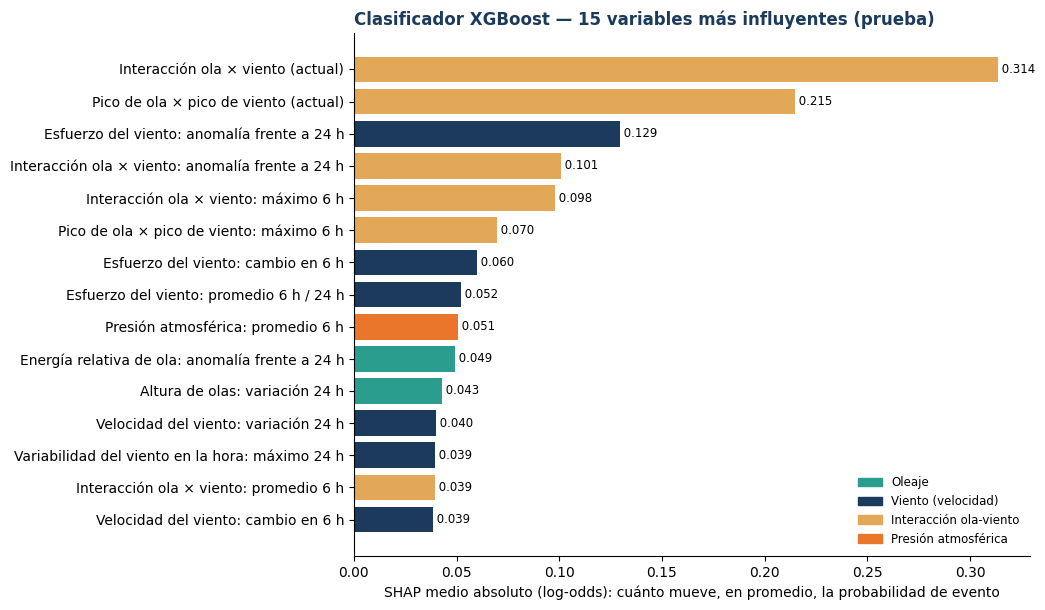

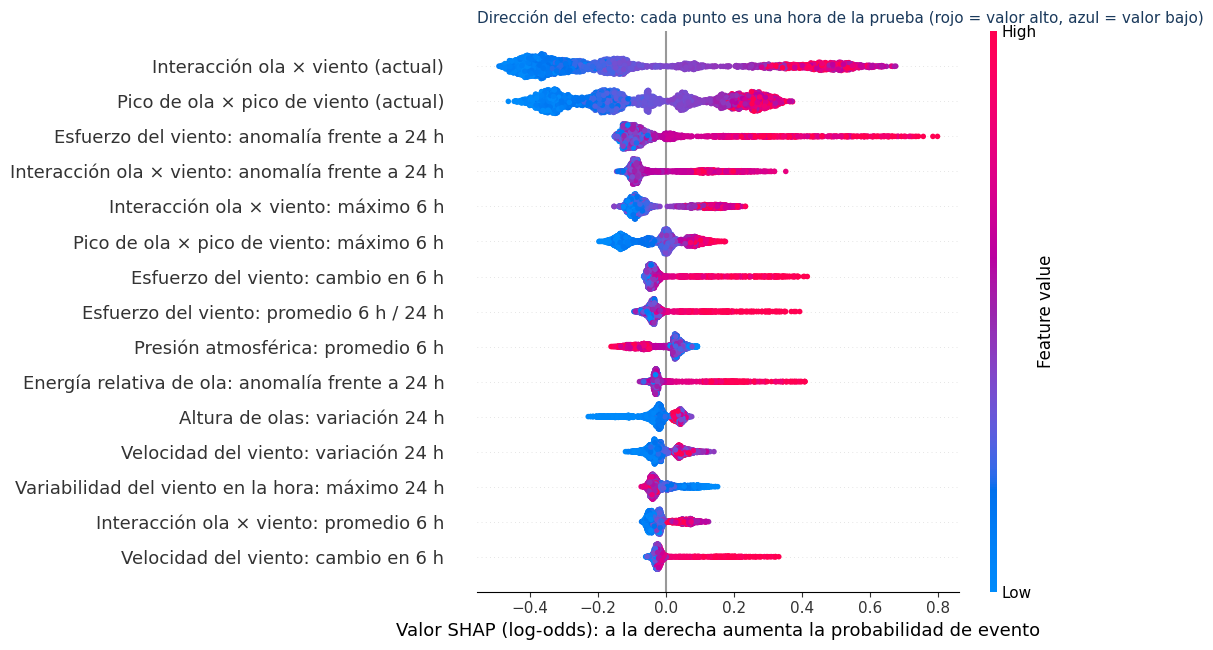

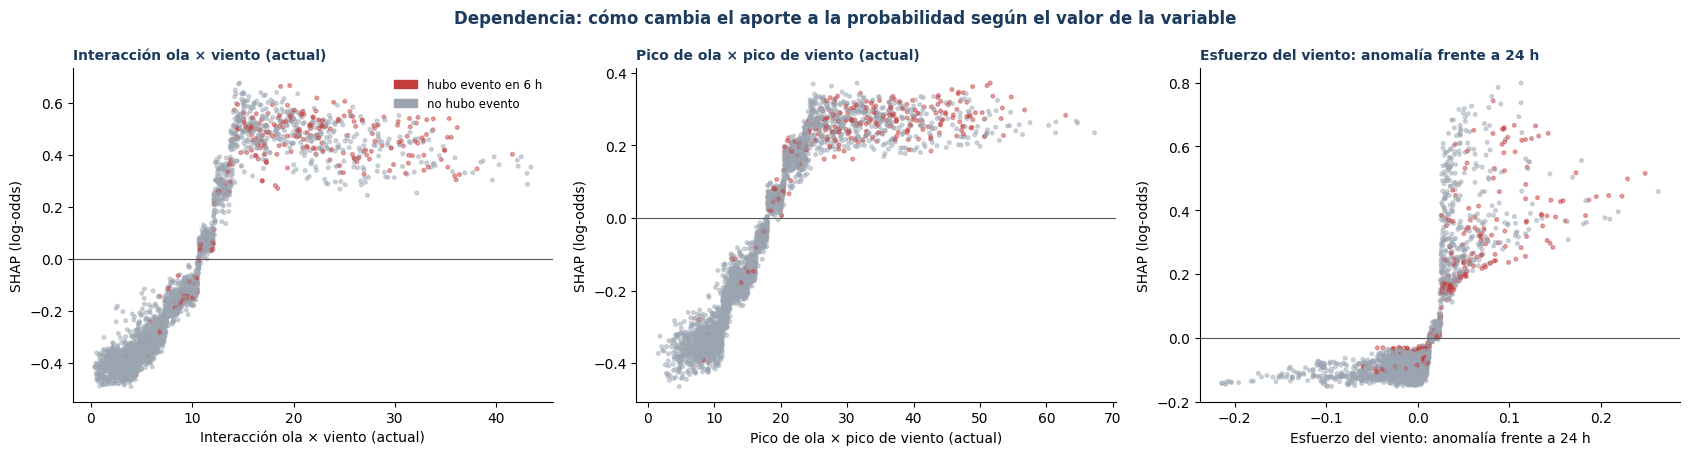

In [14]:
# ==== T17.2 - Clasificador: barras, beeswarm y dependencia ====
TOP = 15
fig, ax = plt.subplots(figsize=(10.5, 6.2))
t = IMP_C.head(TOP)[::-1]
cols_g = {'Oleaje': COLOR_TEAL, 'Viento (velocidad)': COLOR_NAVY, 'Viento (dirección y componentes)': '#5B7FA6', 'Interacción ola-viento': COLOR_GOLD,
          'Presión atmosférica': COLOR_ORANGE, 'Temperatura': COLOR_RED, 'Humedad relativa': COLOR_GRAY}
ax.barh(t['nombre'], t['SHAP_medio_abs'], color=[cols_g[g] for g in t['grupo']])
for y_, v in enumerate(t['SHAP_medio_abs']): ax.text(v, y_, f' {v:.3f}', va='center', fontsize=8.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in cols_g.items() if g in set(t['grupo'])], frameon=False, fontsize=8.5, loc='lower right')
ax.set_xlabel('SHAP medio absoluto (log-odds): cuánto mueve, en promedio, la probabilidad de evento')
ax.set_title(f'Clasificador XGBoost — {TOP} variables más influyentes (prueba)', loc='left', fontsize=12, color=COLOR_NAVY, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.show()

plt.figure()
shap.summary_plot(SV_C, Xc, feature_names=[nombre(c) for c in Xc.columns], max_display=TOP, show=False, plot_size=(11, 6.6))
plt.title('Dirección del efecto: cada punto es una hora de la prueba (rojo = valor alto, azul = valor bajo)', fontsize=11, color=COLOR_NAVY, loc='left')
plt.xlabel('Valor SHAP (log-odds): a la derecha aumenta la probabilidad de evento'); plt.tight_layout(); plt.show()

top3 = IMP_C['variable'].head(3).tolist()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, c in zip(axes, top3):
    j = list(Xc.columns).index(c)
    ax.scatter(Xc[c], SV_C[:, j], s=7, alpha=0.45, c=np.where(yc_v == 1, COLOR_RED, COLOR_GRAY))
    ax.axhline(0, color='#555', lw=0.8)
    ax.set_xlabel(nombre(c)); ax.set_ylabel('SHAP (log-odds)')
    ax.set_title(nombre(c), loc='left', fontsize=10, color=COLOR_NAVY, fontweight='bold'); ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(handles=[Patch(color=COLOR_RED, label='hubo evento en 6 h'), Patch(color=COLOR_GRAY, label='no hubo evento')], frameon=False, fontsize=8.5)
fig.suptitle('Dependencia: cómo cambia el aporte a la probabilidad según el valor de la variable', fontsize=12, color=COLOR_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

### T17.3 Horas hasta el inicio (GBM)

Recordatorio de HU09: esta salida queda prácticamente al nivel del piso trivial (MAE 1.470 h frente a 1.500 h). Por eso se espera que los valores SHAP sean **pequeños**: las variables mueven poco la predicción respecto de su valor base (≈ el punto medio de la ventana).

Valor base del GBM: 2.96 h · predicciones en prueba entre 2.45 y 3.48 h (desv. 0.22 h) · valores reales entre 0.01 y 5.88 h
Suma media de |SHAP| por fila: 0.699 h — cuánto se aleja, en promedio, la predicción de su valor base


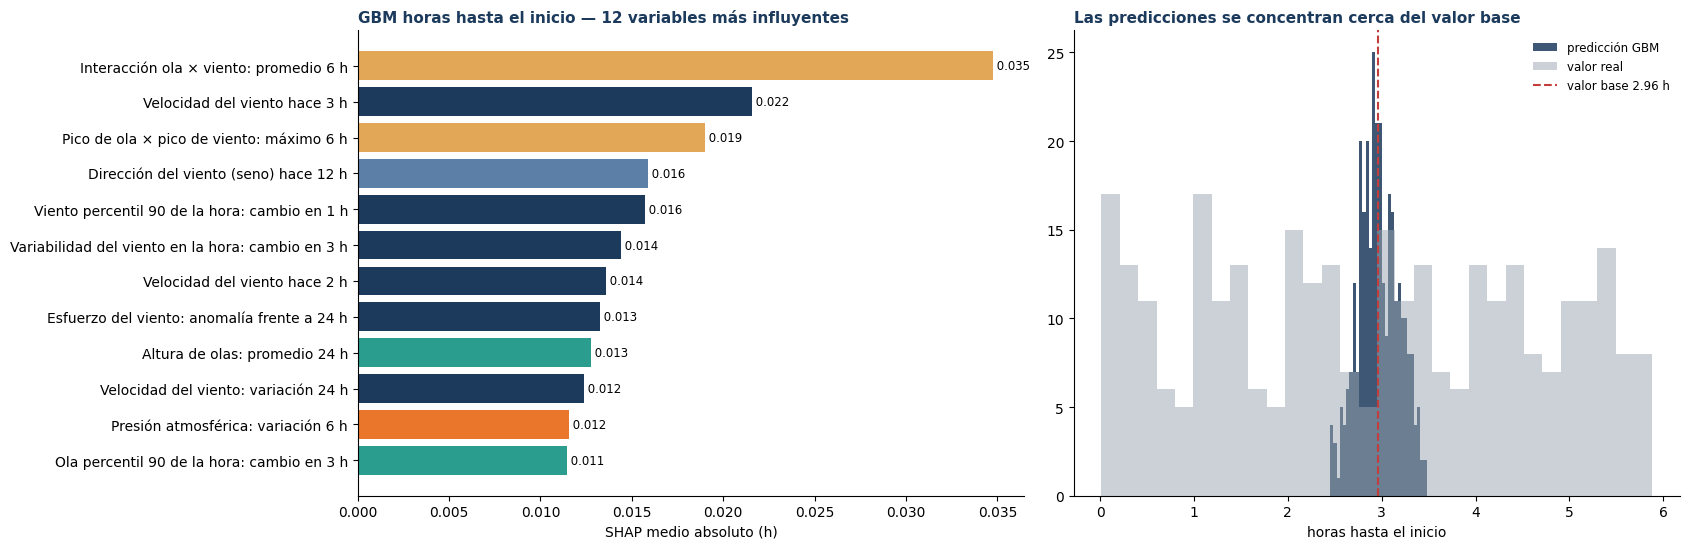

In [15]:
# ==== T17.3 - Horas hasta el inicio ====
pred_h = PRED[(H, 'GBM (modelo principal)')]
print(f'Valor base del GBM: {base_h:.2f} h · predicciones en prueba entre {pred_h.min():.2f} y {pred_h.max():.2f} h '
      f'(desv. {pred_h.std():.2f} h) · valores reales entre {FEAT.loc[MV, H].min():.2f} y {FEAT.loc[MV, H].max():.2f} h')
print(f'Suma media de |SHAP| por fila: {np.abs(SV_H).sum(1).mean():.3f} h — cuánto se aleja, en promedio, la predicción de su valor base')
fig, axes = plt.subplots(1, 2, figsize=(17, 5.6), gridspec_kw={'width_ratios': [1.1, 1]})
t = IMP_H.head(12)[::-1]
axes[0].barh(t['nombre'], t['SHAP_medio_abs'], color=[cols_g[g] for g in t['grupo']])
for y_, v in enumerate(t['SHAP_medio_abs']): axes[0].text(v, y_, f' {v:.3f}', va='center', fontsize=8.5)
axes[0].set_xlabel('SHAP medio absoluto (h)'); axes[0].spines[['top', 'right']].set_visible(False)
axes[0].set_title('GBM horas hasta el inicio — 12 variables más influyentes', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold')
axes[1].hist(pred_h, bins=30, color=COLOR_NAVY, alpha=0.85, label='predicción GBM')
axes[1].hist(FEAT.loc[MV, H], bins=30, color=COLOR_GRAY, alpha=0.5, label='valor real')
axes[1].axvline(base_h, color=COLOR_RED, ls='--', label=f'valor base {base_h:.2f} h')
axes[1].set_xlabel('horas hasta el inicio'); axes[1].legend(frameon=False, fontsize=8.5); axes[1].spines[['top', 'right']].set_visible(False)
axes[1].set_title('Las predicciones se concentran cerca del valor base', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

### T17.4 Duración del evento (GBM sobre la referencia adaptativa)

La predicción de duración tiene **dos componentes**:
1. **Referencia adaptativa**: la duración media de los últimos 10 eventos ya terminados (no es una variable del GBM; es el punto de partida).
2. **Corrección del GBM**: `s · GBM(X)`, con `s = 0.004`, explicada con SHAP.

Para dimensionar cada componente se mide cuánto se aleja cada uno, en promedio, del piso trivial (la media histórica): la referencia mueve la predicción decenas de minutos; la corrección del GBM, segundos.

Piso trivial (media de entrenamiento + validación): 5.67 h · factor de suavizado s = 0.0043


componente,aporte_medio_abs_h,aporte_max_abs_h,aporte_medio_abs_min,porcentaje
Referencia adaptativa (respecto del piso trivial),0.472900,0.873900,28.375300,99.774600
Corrección del GBM (s · GBM),0.001100,0.002200,0.064100,0.225400


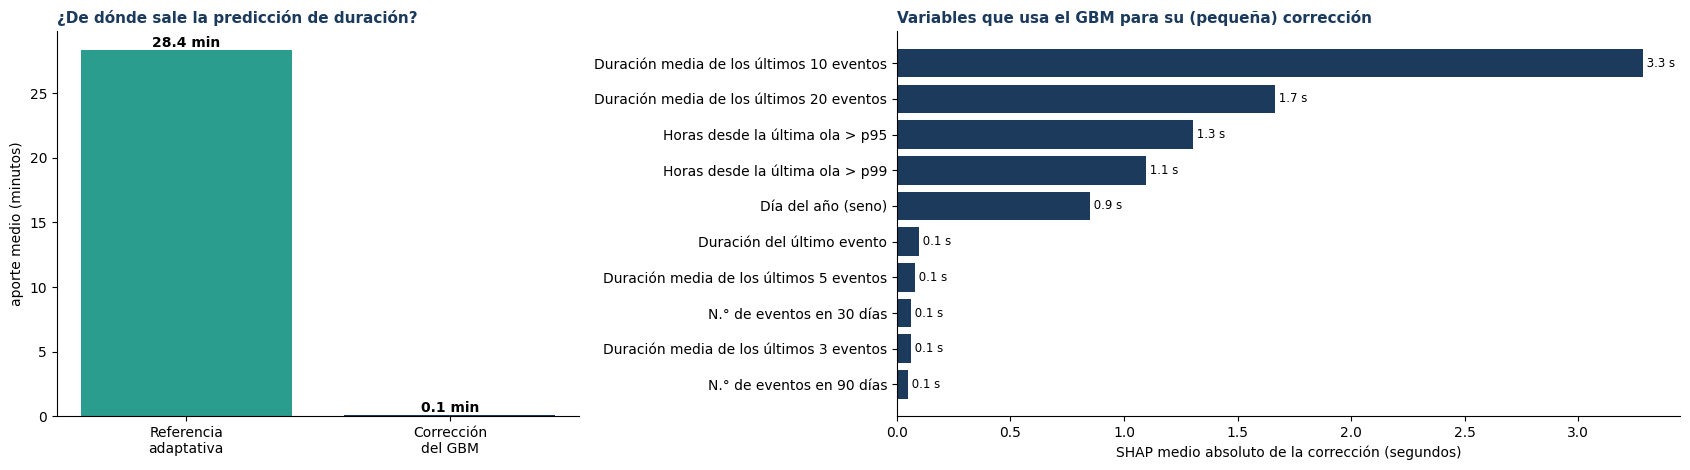

In [16]:
# ==== T17.4 - Duración: referencia vs. corrección del GBM ====
corr_gbm = s_d * m_d.predict(Xd)
piso_d = FIN[D]['piso_h']
DESC_D = pd.DataFrame({
    'componente': ['Referencia adaptativa (respecto del piso trivial)', 'Corrección del GBM (s · GBM)'],
    'aporte_medio_abs_h': [np.abs(REF_D - piso_d).mean(), np.abs(corr_gbm).mean()],
    'aporte_max_abs_h': [np.abs(REF_D - piso_d).max(), np.abs(corr_gbm).max()]})
DESC_D['aporte_medio_abs_min'] = 60 * DESC_D['aporte_medio_abs_h']
DESC_D['porcentaje'] = 100 * DESC_D['aporte_medio_abs_h'] / DESC_D['aporte_medio_abs_h'].sum()
print(f'Piso trivial (media de entrenamiento + validación): {piso_d:.2f} h · factor de suavizado s = {s_d:.4f}')
display(DESC_D.round(4).style.hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={'width_ratios': [0.8, 1.2]})
axes[0].bar(['Referencia\nadaptativa', 'Corrección\ndel GBM'], DESC_D['aporte_medio_abs_min'], color=[COLOR_TEAL, COLOR_NAVY])
for x_, v in enumerate(DESC_D['aporte_medio_abs_min']): axes[0].text(x_, v, f'{v:.1f} min', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_ylabel('aporte medio (minutos)'); axes[0].spines[['top', 'right']].set_visible(False)
axes[0].set_title('¿De dónde sale la predicción de duración?', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold')
t = IMP_D.head(10)[::-1]
axes[1].barh(t['nombre'], 3600 * t['SHAP_medio_abs'], color=COLOR_NAVY)
for y_, v in enumerate(3600 * t['SHAP_medio_abs']): axes[1].text(v, y_, f' {v:.1f} s', va='center', fontsize=8.5)
axes[1].set_xlabel('SHAP medio absoluto de la corrección (segundos)'); axes[1].spines[['top', 'right']].set_visible(False)
axes[1].set_title('Variables que usa el GBM para su (pequeña) corrección', loc='left', fontsize=11, color=COLOR_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

### T17.5 Importancia por sensor de origen y contraste por permutación

**SHAP agrupado:** suma de la importancia SHAP de todas las variables derivadas de un mismo sensor (valor actual, rezagos, promedios, picos…).

**Permutación de grupos (contraste independiente de SHAP):** en la partición de prueba se desordenan al mismo tiempo todas las variables de un grupo (rompiendo su relación con el resultado) y se mide cuánto empeora el modelo: caída del AUC en el clasificador y aumento del MAE en los regresores. Se repite 5 veces y se informa la media. Si ambos métodos coinciden en los grupos más importantes, la interpretación es robusta.

=== Importancia SHAP agrupada por sensor / familia (porcentaje del total de cada modelo) ===


modelo,grupo,n_variables,SHAP_total,porcentaje
"GBM · duración (corrección s·GBM, en h)",Régimen (eventos pasados),7,0.001500,61.897700
"GBM · duración (corrección s·GBM, en h)",Excedencias de ola/viento,4,0.000700,28.171700
"GBM · duración (corrección s·GBM, en h)",Calendario,2,0.000200,9.930600
"GBM · duración (corrección s·GBM, en h)",Estado operativo,6,0.000000,0.000000
GBM · horas hasta el inicio,Viento (velocidad),46,0.208100,29.783100
GBM · horas hasta el inicio,Viento (dirección y componentes),34,0.131700,18.845100
GBM · horas hasta el inicio,Oleaje,42,0.131600,18.833200
GBM · horas hasta el inicio,Interacción ola-viento,12,0.103600,14.820500
GBM · horas hasta el inicio,Presión atmosférica,17,0.051300,7.346200
GBM · horas hasta el inicio,Humedad relativa,13,0.050500,7.230100


=== Permutación de grupos en la partición de prueba (media de 5 repeticiones) ===


grupo,n_variables,empeoramiento_medio,empeoramiento_sd,modelo
Viento (velocidad),46,0.059200,0.002500,Clasificador (caída del AUC)
Interacción ola-viento,12,0.045300,0.002400,Clasificador (caída del AUC)
Oleaje,42,0.042300,0.006200,Clasificador (caída del AUC)
Presión atmosférica,17,0.007200,0.001000,Clasificador (caída del AUC)
Viento (dirección y componentes),34,0.000100,0.000500,Clasificador (caída del AUC)
Temperatura,13,0.000000,0.001000,Clasificador (caída del AUC)
Humedad relativa,13,-0.004900,0.000900,Clasificador (caída del AUC)
Viento (velocidad),46,0.019500,0.003800,"Horas hasta el inicio (aumento del MAE, h)"
Interacción ola-viento,12,0.015200,0.004900,"Horas hasta el inicio (aumento del MAE, h)"
Viento (dirección y componentes),34,0.001600,0.002200,"Horas hasta el inicio (aumento del MAE, h)"


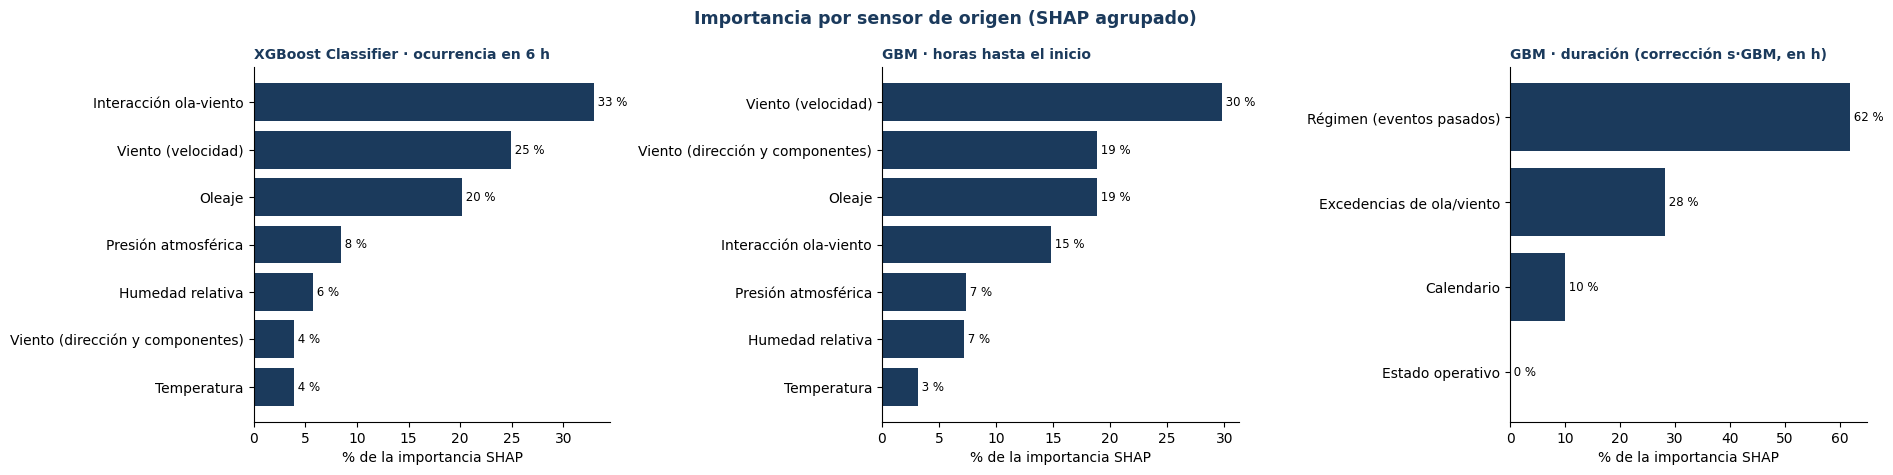

Modelo,Top 3 grupos por SHAP,Top 3 grupos por permutación,Coincidencias (de 3)
Clasificador,"Interacción ola-viento, Viento (velocidad), Oleaje","Viento (velocidad), Interacción ola-viento, Oleaje",3
Horas hasta el inicio,"Viento (velocidad), Viento (dirección y componentes), Oleaje","Viento (velocidad), Interacción ola-viento, Viento (dirección y componentes)",2
Duración,"Régimen (eventos pasados), Excedencias de ola/viento, Calendario","Régimen (eventos pasados), Excedencias de ola/viento, Estado operativo",2


In [17]:
# ==== T17.5 - Importancia por grupo: SHAP agrupado y permutación ====
rng10 = np.random.default_rng(SEMILLA); N_PERM = 5
def permutacion_grupos(X, grupos, metrica, base_valor, mayor_es_mejor):
    filas = []
    for g in sorted(set(grupos.values())):
        cols = [c for c in X.columns if grupos[c] == g]; caidas = []
        for _ in range(N_PERM):
            Xp = X.copy(); idx_p = rng10.permutation(len(X))
            Xp[cols] = X[cols].values[idx_p]
            v = metrica(Xp)
            caidas.append(base_valor - v if mayor_es_mejor else v - base_valor)
        filas.append({'grupo': g, 'n_variables': len(cols), 'empeoramiento_medio': np.mean(caidas), 'empeoramiento_sd': np.std(caidas, ddof=1)})
    return pd.DataFrame(filas).sort_values('empeoramiento_medio', ascending=False)

g_c = {c: sensor(c) for c in Xc.columns}; g_d = {c: sensor(c) for c in Xd.columns}
auc_base = roc_auc_score(yc_v, m_c.predict_proba(Xc)[:, 1])
PERM_C = permutacion_grupos(Xc, g_c, lambda Xp: roc_auc_score(yc_v, m_c.predict_proba(Xp)[:, 1]), auc_base, True).assign(modelo='Clasificador (caída del AUC)')
y_h, y_d = FEAT.loc[MV, H].values, FEAT.loc[MV, D].values
mae_h = mean_absolute_error(y_h, m_h.predict(Xh))
PERM_H = permutacion_grupos(Xh, g_c, lambda Xp: mean_absolute_error(y_h, m_h.predict(Xp)), mae_h, False).assign(modelo='Horas hasta el inicio (aumento del MAE, h)')
mae_d = mean_absolute_error(y_d, REF_D + s_d * m_d.predict(Xd))
PERM_D = permutacion_grupos(Xd, g_d, lambda Xp: mean_absolute_error(y_d, REF_D + s_d * m_d.predict(Xp)), mae_d, False).assign(modelo='Duración (aumento del MAE, h)')
PERM = pd.concat([PERM_C, PERM_H, PERM_D], ignore_index=True)

GRUPOS = pd.concat([t.groupby(['modelo', 'grupo'], as_index=False).agg(n_variables=('variable', 'size'), SHAP_total=('SHAP_medio_abs', 'sum'), porcentaje=('porcentaje', 'sum'))
                    for t in (IMP_C, IMP_H, IMP_D)]).sort_values(['modelo', 'SHAP_total'], ascending=[True, False])
print('=== Importancia SHAP agrupada por sensor / familia (porcentaje del total de cada modelo) ===')
display(GRUPOS.round(4).style.hide(axis='index'))
print('=== Permutación de grupos en la partición de prueba (media de 5 repeticiones) ===')
display(PERM.round(4).style.hide(axis='index'))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, (mod, tg), (pm, tp) in zip(axes, [(m, GRUPOS[GRUPOS['modelo'] == m]) for m in [IMP_C['modelo'][0], IMP_H['modelo'][0], IMP_D['modelo'][0]]],
                                   [(None, PERM_C), (None, PERM_H), (None, PERM_D)]):
    tg = tg.sort_values('porcentaje'); ax.barh(tg['grupo'], tg['porcentaje'], color=COLOR_NAVY)
    for y_, v in enumerate(tg['porcentaje']): ax.text(v, y_, f' {v:.0f} %', va='center', fontsize=8.5)
    ax.set_xlabel('% de la importancia SHAP'); ax.set_title(mod, loc='left', fontsize=10, color=COLOR_NAVY, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Importancia por sensor de origen (SHAP agrupado)', fontsize=12.5, color=COLOR_NAVY, fontweight='bold'); plt.tight_layout(); plt.show()

# Coincidencia entre SHAP agrupado y permutación (orden de los 3 grupos principales)
coinc = []
for nom, imp, pm in [('Clasificador', IMP_C, PERM_C), ('Horas hasta el inicio', IMP_H, PERM_H), ('Duración', IMP_D, PERM_D)]:
    top_s = imp.groupby('grupo')['SHAP_medio_abs'].sum().sort_values(ascending=False).index[:3].tolist()
    top_p = pm['grupo'].head(3).tolist()
    coinc.append([nom, ', '.join(top_s), ', '.join(top_p), len(set(top_s) & set(top_p))])
display(pd.DataFrame(coinc, columns=['Modelo', 'Top 3 grupos por SHAP', 'Top 3 grupos por permutación', 'Coincidencias (de 3)']).style.hide(axis='index'))

### T17.6 Explicación de casos individuales (clasificador)

Dos horas de la prueba explicadas variable por variable (gráfico *waterfall*): parte del valor base y muestra qué variables subieron (rojo) o bajaron (azul) la probabilidad hasta llegar a la predicción.
- **Caso A:** un evento bien anticipado: no había un evento en curso, la probabilidad superó el umbral y efectivamente empezó un evento en las 6 h siguientes.
- **Caso B:** una falsa alarma: no había un evento en curso y la probabilidad superó el umbral, pero no empezó ningún evento (se elige a más de 7 días del caso A).

A · evento bien anticipado: 14-07-2026 09:00 · probabilidad 0.760 (umbral 0.14) · sin evento en curso · ¿empezó un evento en las 6 h siguientes? sí


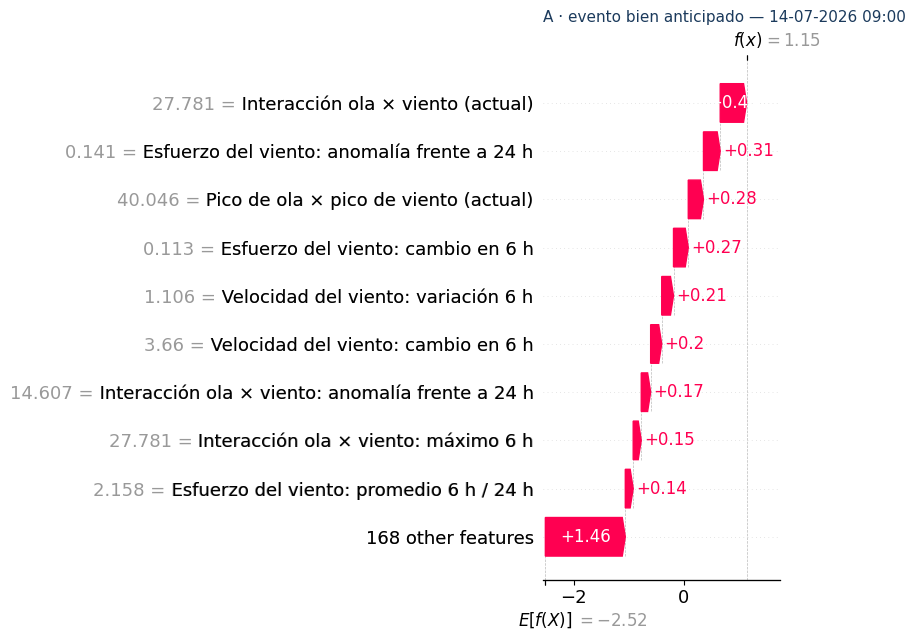

B · falsa alarma: 17-05-2026 13:00 · probabilidad 0.558 (umbral 0.14) · sin evento en curso · ¿empezó un evento en las 6 h siguientes? no


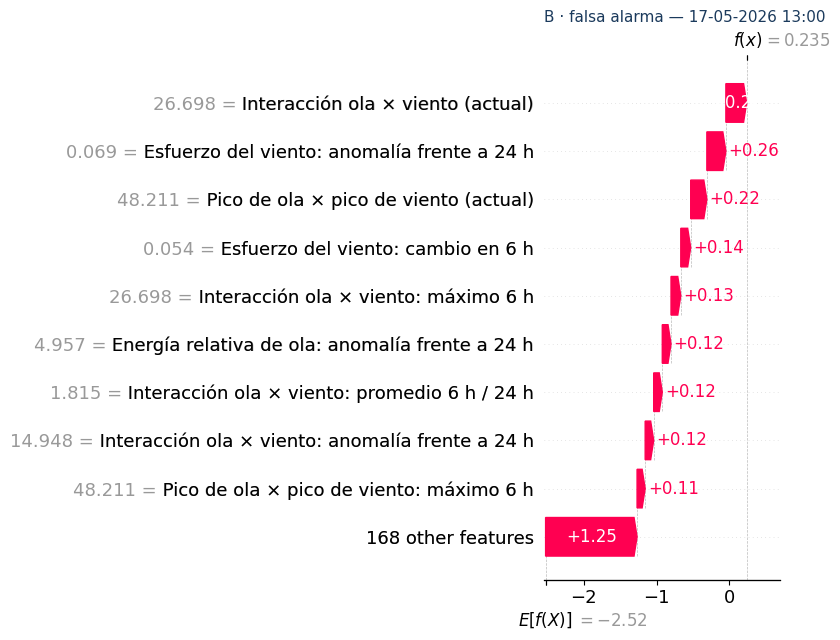

In [18]:
# ==== T17.6 - Casos individuales ====
p_c = PROB['XGBoost (modelo principal)']; u_c = FIN[TARGET_CLF]['umbral']
# Solo horas sin un evento en curso (la pregunta es si EMPEZARÁ uno nuevo) y casos separados al menos 7 días
sin_evento = OPER.loc[Xc.index, 'evento_en_curso'].values == 0
aciertos = np.where((yc_v == 1) & (p_c >= u_c) & sin_evento)[0]
i_a = aciertos[np.argmax(p_c[aciertos])]
lejos = np.abs((Xc.index - Xc.index[i_a]) / pd.Timedelta(days=1)) >= 7
falsas = np.where((yc_v == 0) & (p_c >= u_c) & sin_evento & lejos)[0]
casos = {'A · evento bien anticipado': i_a, 'B · falsa alarma': falsas[np.argmax(p_c[falsas])]}
expl = shap.Explanation(values=SV_C, base_values=np.full(len(SV_C), base_c), data=Xc.values, feature_names=[nombre(c) for c in Xc.columns])
CASOS = []
for etq, i in casos.items():
    print(f"{etq}: {Xc.index[i]:%d-%m-%Y %H:%M} · probabilidad {p_c[i]:.3f} (umbral {u_c}) · sin evento en curso · ¿empezó un evento en las 6 h siguientes? {'sí' if yc_v[i] else 'no'}")
    plt.figure(); shap.plots.waterfall(expl[i], max_display=10, show=False)
    plt.title(f'{etq} — {Xc.index[i]:%d-%m-%Y %H:%M}', fontsize=11, color=COLOR_NAVY, loc='left'); plt.tight_layout(); plt.show()
    orden = np.argsort(-np.abs(SV_C[i]))[:5]
    CASOS.append({'caso': etq, 'fecha_hora': Xc.index[i], 'probabilidad': p_c[i], 'hubo_evento': int(yc_v[i]),
                  'variables_principales': '; '.join(f'{nombre(Xc.columns[j])} ({SV_C[i, j]:+.2f})' for j in orden)})
CASOS = pd.DataFrame(CASOS)

### T17.7 Lectura operativa para el Gerente de operaciones

Traducción de los resultados a lenguaje operativo: qué variables mira el modelo y en qué dirección empujan la predicción. La dirección se calcula con la correlación de Spearman entre el valor de la variable y su valor SHAP en la prueba (ρ > 0.3: a mayor valor, mayor predicción; ρ < −0.3: a mayor valor, menor predicción; en otro caso, efecto no monótono).

In [21]:
# ==== T17.7 - Tabla de lectura operativa ====
def direccion(rho, salida):
    sube = {'clf': 'aumenta la probabilidad de evento', 'h': 'alarga el tiempo hasta el inicio', 'd': 'alarga la duración estimada'}[salida]
    baja = {'clf': 'disminuye la probabilidad de evento', 'h': 'acerca el inicio', 'd': 'acorta la duración estimada'}[salida]
    if rho > 0.3: return f'A mayor valor, {sube}'
    if rho < -0.3: return f'A mayor valor, {baja}'
    return 'Efecto no monótono (depende del rango de valores)'
filas = []
for imp, sal, etq in [(IMP_C, 'clf', 'Ocurrencia en 6 h (XGBoost)'), (IMP_H, 'h', 'Horas hasta el inicio (GBM)')]:
    for _, r in imp.head(5).iterrows():
        filas.append([etq, r['nombre'], r['grupo'], f"{r['porcentaje']:.1f} %", direccion(r['direccion_rho'], sal)])
# Duración: el componente principal es la referencia adaptativa; el GBM solo aporta una corrección de segundos
rho_ref = spearmanr(REF_D, PRED[(D, 'GBM (modelo principal)')]).correlation
filas.append(['Duración (GBM sobre referencia)', 'Duración media de los últimos 10 eventos (referencia adaptativa)', 'Régimen (eventos pasados)',
              f"{DESC_D['porcentaje'].iloc[0]:.1f} % del ajuste frente al piso",
              f'Punto de partida de la predicción: a mayor duración media reciente, mayor duración estimada (ρ = {rho_ref:.2f})'])
for _, r in IMP_D.head(3).iterrows():
    filas.append(['Duración (GBM sobre referencia)', r['nombre'] + ' (corrección del GBM)', r['grupo'],
                  f"{r['porcentaje']:.1f} % de una corrección de ≈ {60 * DESC_D['aporte_medio_abs_h'].iloc[1]:.2f} min",
                  'Ajuste mínimo, sin efecto operativo apreciable'])
LECTURA = pd.DataFrame(filas, columns=['Salida', 'Variable', 'Sensor / familia', '% de la importancia', 'Cómo influye'])
display(LECTURA.style.hide(axis='index'))
gtop = GRUPOS[GRUPOS['modelo'] == IMP_C['modelo'][0]].sort_values('porcentaje', ascending=False)
print(f"Clasificador: los dos grupos más influyentes son {gtop['grupo'].iloc[0]} ({gtop['porcentaje'].iloc[0]:.0f} %) y "
      f"{gtop['grupo'].iloc[1]} ({gtop['porcentaje'].iloc[1]:.0f} %). Duración: la referencia adaptativa aporta el "
      f"{DESC_D['porcentaje'].iloc[0]:.1f} % del ajuste frente al piso y la corrección del GBM el {DESC_D['porcentaje'].iloc[1]:.1f} %.")

Salida,Variable,Sensor / familia,% de la importancia,Cómo influye
Ocurrencia en 6 h (XGBoost),Interacción ola × viento (actual),Interacción ola-viento,11.4 %,"A mayor valor, aumenta la probabilidad de evento"
Ocurrencia en 6 h (XGBoost),Pico de ola × pico de viento (actual),Interacción ola-viento,7.8 %,"A mayor valor, aumenta la probabilidad de evento"
Ocurrencia en 6 h (XGBoost),Esfuerzo del viento: anomalía frente a 24 h,Viento (velocidad),4.7 %,"A mayor valor, aumenta la probabilidad de evento"
Ocurrencia en 6 h (XGBoost),Interacción ola × viento: anomalía frente a 24 h,Interacción ola-viento,3.7 %,"A mayor valor, aumenta la probabilidad de evento"
Ocurrencia en 6 h (XGBoost),Interacción ola × viento: máximo 6 h,Interacción ola-viento,3.6 %,"A mayor valor, aumenta la probabilidad de evento"
Horas hasta el inicio (GBM),Interacción ola × viento: promedio 6 h,Interacción ola-viento,5.0 %,"A mayor valor, acerca el inicio"
Horas hasta el inicio (GBM),Velocidad del viento hace 3 h,Viento (velocidad),3.1 %,"A mayor valor, acerca el inicio"
Horas hasta el inicio (GBM),Pico de ola × pico de viento: máximo 6 h,Interacción ola-viento,2.7 %,"A mayor valor, acerca el inicio"
Horas hasta el inicio (GBM),Dirección del viento (seno) hace 12 h,Viento (dirección y componentes),2.3 %,"A mayor valor, acerca el inicio"
Horas hasta el inicio (GBM),Viento percentil 90 de la hora: cambio en 1 h,Viento (velocidad),2.3 %,"A mayor valor, alarga el tiempo hasta el inicio"


Clasificador: los dos grupos más influyentes son Interacción ola-viento (33 %) y Viento (velocidad) (25 %). Duración: la referencia adaptativa aporta el 99.8 % del ajuste frente al piso y la corrección del GBM el 0.2 %.


### Exportación, verificaciones y Definition of Done — HU10 (T17)

| Archivo | Contenido |
|---|---|
| `importancia_shap_HU10.csv` | SHAP medio absoluto, porcentaje, grupo y dirección de cada variable, para los tres modelos |
| `importancia_grupos_HU10.csv` | Importancia SHAP agrupada por sensor / familia |
| `permutacion_grupos_HU10.csv` | Empeoramiento en prueba al permutar cada grupo de variables |
| `descomposicion_duracion_HU10.csv` | Aporte de la referencia adaptativa frente a la corrección del GBM |
| `lectura_operativa_HU10.csv` · `casos_individuales_HU10.csv` | Tabla para el Gerente de operaciones y casos explicados |

In [20]:
# ==== HU10 - Exportación, verificaciones y DoD ====
pd.concat([IMP_C, IMP_H, IMP_D], ignore_index=True).to_csv('importancia_shap_HU10.csv', index=False)
GRUPOS.to_csv('importancia_grupos_HU10.csv', index=False); PERM.to_csv('permutacion_grupos_HU10.csv', index=False)
DESC_D.to_csv('descomposicion_duracion_HU10.csv', index=False); LECTURA.to_csv('lectura_operativa_HU10.csv', index=False)
CASOS.to_csv('casos_individuales_HU10.csv', index=False)
archivos_hu10 = ['importancia_shap_HU10.csv', 'importancia_grupos_HU10.csv', 'permutacion_grupos_HU10.csv', 'descomposicion_duracion_HU10.csv',
                 'lectura_operativa_HU10.csv', 'casos_individuales_HU10.csv']
print('Archivos generados:')
for f in archivos_hu10: print(f'  - {f}  ({Path(f).stat().st_size / 1024:,.0f} KB)')

chequeos_hu10 = {
    'Se interpretan los modelos finales de HU09 (GBM y XGBoost Classifier del .joblib)': FIN[H]['algoritmo'] == 'GBM' and FIN[D]['algoritmo'] == 'GBM' and FIN[TARGET_CLF]['algoritmo'] == 'XGBoost',
    'Los modelos cargados reproducen las predicciones de HU09': True,
    'SHAP es aditivo (valor base + suma de SHAP = predicción) en los tres modelos': max(err_c, err_h, err_d) < 1e-3,
    'Importancia calculada para todas las variables de cada modelo': len(IMP_C) == Xc.shape[1] and len(IMP_H) == Xh.shape[1] and len(IMP_D) == Xd.shape[1],
    'Contraste por permutación de grupos en la partición de prueba': len(PERM) > 0,
    'Lectura operativa generada para las tres salidas': LECTURA['Salida'].nunique() == 3,
}
for k, v in chequeos_hu10.items(): assert v, f'FALLA: {k}'
print(f'\n{len(chequeos_hu10)} verificaciones de HU10 superadas.')
display(pd.DataFrame([
    ['T17', 'Importancia de variables (SHAP) de los tres modelos finales', 'CUMPLE', 'importancia_shap_HU10.csv'],
    ['T17', 'Dirección del efecto y dependencia de las variables principales', 'CUMPLE', 'gráficos beeswarm y de dependencia'],
    ['T17', 'Importancia por sensor y contraste por permutación', 'CUMPLE', 'importancia_grupos_HU10.csv · permutacion_grupos_HU10.csv'],
    ['T17', 'Explicación de casos individuales', 'CUMPLE', 'casos_individuales_HU10.csv'],
    ['HU10', 'Lectura comprensible para el Gerente de operaciones', 'CUMPLE', 'lectura_operativa_HU10.csv'],
], columns=['Tarea', 'Criterio', 'Estado', 'Evidencia']).style.hide(axis='index'))

Archivos generados:
  - importancia_shap_HU10.csv  (63 KB)
  - importancia_grupos_HU10.csv  (2 KB)
  - permutacion_grupos_HU10.csv  (2 KB)
  - descomposicion_duracion_HU10.csv  (0 KB)
  - lectura_operativa_HU10.csv  (2 KB)
  - casos_individuales_HU10.csv  (1 KB)

6 verificaciones de HU10 superadas.


Tarea,Criterio,Estado,Evidencia
T17,Importancia de variables (SHAP) de los tres modelos finales,CUMPLE,importancia_shap_HU10.csv
T17,Dirección del efecto y dependencia de las variables principales,CUMPLE,gráficos beeswarm y de dependencia
T17,Importancia por sensor y contraste por permutación,CUMPLE,importancia_grupos_HU10.csv · permutacion_grupos_HU10.csv
T17,Explicación de casos individuales,CUMPLE,casos_individuales_HU10.csv
HU10,Lectura comprensible para el Gerente de operaciones,CUMPLE,lectura_operativa_HU10.csv


## 5.4 Conclusiones de HU10 (resultados de esta ejecución)

*Cifras obtenidas con los archivos de EXPORTACIONES_01/02 y los modelos de `modelos_finales_HU09.joblib`; al re-ejecutar en Colab pueden variar ligeramente según las versiones de las librerías.*

> ### ✅ Respuesta para el Gerente de operaciones
> **Lo que más influye en la predicción de un evento en las próximas 6 horas es la combinación de oleaje y viento.** El producto ola × viento y sus picos explican alrededor de un tercio de la decisión del clasificador, seguidos por la velocidad del viento y el oleaje por separado. Influyen especialmente los **aumentos bruscos** respecto de las últimas 24 h. La dirección del viento, la temperatura y la humedad casi no influyen.

| Salida | Lo que más influye (SHAP) | Contraste por permutación (prueba) | Lectura |
|---|---|---|---|
| **Ocurrencia en 6 h (XGBoost)** | Interacción ola-viento **33 %**, viento (velocidad) **25 %**, oleaje **20 %**, presión 8 % | Al desordenar las variables de viento, el AUC cae 0.059; las de interacción ola-viento, 0.045; las de oleaje, 0.042; las de dirección, temperatura y humedad, ≈ 0 | **Coinciden los 3 grupos principales.** A mayor oleaje y viento (y mayor subida respecto de las últimas 24 h), mayor probabilidad de evento; a mayor presión media de 6 h, menor probabilidad (las bajas presiones acompañan al mal tiempo) |
| **Horas hasta el inicio (GBM)** | Viento (velocidad) 30 %, dirección del viento 19 %, oleaje 19 %, interacción 15 % | Desordenar cualquier grupo aumenta el MAE en 0.02 h o menos | Las variables mueven poco la predicción: se queda entre 2.45 y 3.48 h (valor base 2.96 h), mientras que los valores reales van de 0 a 5.9 h. **Confirma la limitación de HU09**: es una estimación aproximada. La tendencia es razonable: más viento y oleaje acercan el inicio |
| **Duración (GBM sobre la referencia)** | **Referencia adaptativa: 99.8 %** del ajuste frente al piso (≈ 28 min en promedio); corrección del GBM: 0.2 % (≈ 4 s) | Desordenar las variables del GBM cambia el MAE en menos de 0.001 h | La duración estimada es, en la práctica, la **duración media de los últimos 10 eventos**. Coincide con lo declarado en HU08/HU09: la mejora viene del esquema, no del algoritmo |

**Implicaciones para el documento:**
1. **OE1 (variables relevantes):** SHAP confirma que el **oleaje** y la **velocidad del viento**, en especial actuando juntos, son las variables más influyentes en la anticipación de eventos, en concordancia con la literatura revisada (efectos compuestos ola-viento).
2. **Coherencia física:** las direcciones encontradas son razonables para un terminal expuesto a oleaje y viento: más ola, más viento y baja presión se asocian con mayor probabilidad de evento.
3. **Alcance:** SHAP explica **cómo usa el modelo** las variables (asociación), **no** demuestra causalidad. Las variables del datalogger (temperatura interna y voltaje) no participan porque en HU05 se definieron como variables de diagnóstico del equipo, no como predictores.
4. **Para HU12 (dashboard):** se recomienda mostrar, junto con la probabilidad de evento, las 3–5 variables que más la explican en cada hora (como en los casos A y B), para que Operaciones entienda por qué el modelo emite una alerta.

**Referencias:**
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*, 4765–4774.
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9